# CosMx: malignant-marker expression in fibroblasts across cleaning methods

Adapted from [cellAdmix NSCLC full-data tutorial](/home/jwinchel/cellAdmix/vignettes/NSCLC_tutorial_fulldata_back.ipynb), especially cells 4–16 and 27–33, and its `R/vignette_helpers.R`.

## Questions reproduced
1. Where are fibroblasts and the annotated tumor/stroma regions?
2. Do fibroblasts in **tumor interior** express more malignant markers than those in **stroma**?
3. Does each cleaning method reduce those markers while preserving native fibroblast markers?
4. How do tumor-versus-stroma differential-expression scores change after cleaning?

The tutorial's exact malignant/native marker lists and `niche` region mapping are used. All eight CosMx slices are processed independently. Cell labels come from the final AnnData (`cell_type_harmonized == 'Fibroblast'`). Existing corrected matrices are used; CellAdmix is the current 1.5×cell-type-factor/automated-bridge run, not the tutorial's manually selected factor. Factor-loading and CRF plots are specific to CellAdmix and are not generalized to methods that do not produce those quantities.

**DE adaptation:** Pagoda2 is absent from the available R environment. This notebook uses Scanpy's two-sided Wilcoxon test, tie correction and BH adjustment, after library-size normalization and log1p. Its Z scores are Wilcoxon statistics, not Pagoda2's adjusted Z scores; numerical reproduction of Pagoda2 is not claimed. Volcano plots use BH-adjusted P values and approximate log2 fold changes. The tutorial's expression bars are reproduced as mean **per-cell transcript fractions**; absolute mean counts and detection fractions are also saved because an increased fraction need not mean more transcripts.

**Fair comparison:** within each slice, use the intersection of fibroblasts passing ≥10 counts and ≥5 expressed genes in every available selected method. Tumor/stroma assignments remain fixed. Missing methods are explicitly reported and do not eliminate the entire slice. Repeated slices are not independent donors; cross-slice plots are descriptive, without a pooled significance test. ResolVI outputs are inferred expression rates, so positive detection and cell-level P values need particular care.

Run in the `rctd` Python environment. Results are cached in a new settings/input-specific directory and existing results are preserved.

**Syndri probability safeguard:** `SYNDRI_MIN_PROBABILITY = 0.7` protects cell–gene entries below 0.7 from removal. The fixed removal target remains `SYNDRI_TARGET = 0.5`; that target may be unattainable if too few counts are eligible. This setting applies to both slice-specific and pooled cleaning, and is included in the cache key.


In [40]:
from pathlib import Path
from types import SimpleNamespace
import sys, json, hashlib, re, gc
import numpy as np
import pandas as pd
import anndata as ad
import scanpy as sc
import h5py
from scipy import sparse
from scipy.stats import norm
import matplotlib.pyplot as plt
from IPython.display import display
import matplotlib.font_manager as fm
import matplotlib as mpl

font_path = '/home/jwinchel/fonts/ARIAL.TTF'  
fm.fontManager.addfont(font_path)
mpl.rcParams['svg.fonttype'] = 'none'
# Set Arial globally
plt.rcParams['font.family'] = 'Arial'

PROJECT = Path('/home/jwinchel/Syndri')
DATA_ROOT = Path('/work/magroup/skrieger/Syndri/data/datasets')
ROOT = DATA_ROOT / 'nsclc_cosmx/results'
sys.path.insert(0, str(PROJECT/'eval'))
from metrics_eval import cleaned_counts_for_removed_fraction_maybe_grouped

REPO = Path('/home/jwinchel/Syndri')
FIGURE_DIR = REPO / 'figures' / 'outputs'
METHODS = ['Raw', 'SPLIT', 'ResolVI', 'ovrlpy 0.7', 'CellAdmix', 'Syndri']
SLICE_SUBSET = None  # None = all eight; otherwise stems such as ['st_integrated_slice-Lung12']
PLOT_SLICE = 'st_integrated_slice-Lung5_Rep1'  # All slices are calculated/exported; choose one for inline panels.
MIN_COUNTS, MIN_GENES, MIN_GROUP_SIZE = 10, 5, 30
NORMALIZE_TARGET = 10_000
VOLCANO_X_LIMIT = 5.0  # Display only: extreme fold changes are clipped and counted per panel.
SYNDRI_TARGET = 0.5
SYNDRI_MIN_PROBABILITY = 0.5 # Protect genes with admixture probabilities below this value.
CLEAN_ARGS = SimpleNamespace(cell_type_specific_removal=True, cleaning_mode='zero',
    probability_transform='power', probability_power=2., clean_prob_threshold=SYNDRI_MIN_PROBABILITY)
if not 0 <= SYNDRI_MIN_PROBABILITY <= 1:
    raise ValueError('SYNDRI_MIN_PROBABILITY must be between 0 and 1')
CFG = {'label': 'cell_type_harmonized', 'xy': ['CenterX_global_px', 'CenterY_global_px']}
COLORS = {'Raw':'#5cafe0','ResolVI':'#9046ad','ovrlpy 0.5':'#ff953e','ovrlpy 0.7':'#ffdf71',
          'SPLIT':'#20b1a9','CellAdmix':'#d87ba3','Syndri':'#4056a1'}
EXTERNAL = {'ResolVI':('resolvi','resolvi_corrected_counts'),
    # 'ovrlpy 0.5':('ovrlpy_pixel_correction','ovrlpy_corrected_counts_vsi_lt_0_5'),
    'ovrlpy 0.7':('ovrlpy_pixel_correction','ovrlpy_corrected_counts_vsi_lt_0_7'),
    'CellAdmix':('celladmix_k1p5ct','celladmix_corrected_counts')}
TUMOR_MARKERS = ['KRT19','KRT8','KRT18','TACSTD2','CEACAM6','CDH1','EPCAM','CLDN4','SFN','PHLDA2',
    'DDR1','AGR2','KRT6A','KRT17','CD24','KRT5','AQP3','SLC2A1','KRT7','COL17A1','FASN','KRT15','ITGA2',
    'ERBB3','S100A2','SPINK1','ITGB4','PIGR','SOX2','ITGA3','CYSTM1','NTRK2','MAPK13','CCND1','HDAC1','EGFR']

ADMIX_MARKERS = ['KRT19','KRT8','KRT17','CEACAM6']
NATIVE_MARKERS = ['MYL9','CXCL12','PDGFRB','RARRES2','CDH11']
# Fibroblast programs to label on the Syndri volcano and Z plots.
TUMOR_REGION_FIBROBLAST_MARKERS = ['IGFBP5', 'COL4A2', 'IGFBP3', 'FN1', 'BGN']
STROMAL_FIBROBLAST_MARKERS = ['DCN', 'COL14A1', 'FOS', 'MMP2', 'DUSP1']
FIBROBLAST_TUMOR_COLOR = '#b23a48'
FIBROBLAST_STROMAL_COLOR = '#287a69'
# Macrophage markers present in the measured CosMx gene panel (checked in Lung5 Rep1).
MACROPHAGE_MARKERS = ['TYROBP','FCER1G','CD68','CSF1R','C1QA','C1QB','C1QC','CD163','MRC1','CD14','ITGAM']
plt.rcParams.update({'pdf.fonttype':42,'svg.fonttype':'none','font.size':10})


In [2]:
def file_signature(path):
    path = Path(path)
    st = path.stat()
    return {'path': str(path.resolve()), 'size': st.st_size, 'mtime_ns': st.st_mtime_ns}

def read_metadata(path):
    with h5py.File(path, 'r') as f:
        return ad.io.read_elem(f['obs']), ad.io.read_elem(f['var'])

def read_matrix(path, layer=None):
    # Read one matrix only: loading an entire h5ad also loads large probability layers.
    with h5py.File(path, 'r') as f:
        key = 'X' if layer is None else f'layers/{layer}'
        if key not in f:
            raise KeyError(f'{path}: missing {key}')
        return sparse.csr_matrix(ad.io.read_elem(f[key]))

def method_counts(method, path, raw, obs, var, cfg):
    if method == 'Raw':
        return raw.copy(), obs.index
    if method == 'SPLIT':
        return read_matrix(path, 'split_purified_counts_X'), obs.index
    if method == 'Syndri':
        probabilities = read_matrix(path, 'syndri_admix_probs_X')
        cleaned = cleaned_counts_for_removed_fraction_maybe_grouped(
            raw, probabilities, SYNDRI_TARGET, CLEAN_ARGS, labels=obs[cfg['label']])[0]
        return sparse.csr_matrix(cleaned), obs.index
    directory, layer = EXTERNAL[method]
    source = path.parent.parent / 'competitors' / directory / path.name
    if not source.exists(): return None, None
    ext_obs, ext_var = read_metadata(source)
    if not ext_obs.index.is_unique or not ext_var.index.is_unique:
        raise ValueError(f'Duplicate IDs in {source}')
    missing_genes = var.index.difference(ext_var.index)
    if len(missing_genes): raise ValueError(f'{source}: {len(missing_genes)} raw genes missing; choose a common panel explicitly.')
    names = obs.index[obs.index.isin(ext_obs.index)]
    counts = read_matrix(source, layer)
    return counts[ext_obs.index.get_indexer(names)][:, ext_var.index.get_indexer(var.index)], names

def resolved_gene_symbols(var):
    """Resolve annotation placeholders using symbol-valued feature IDs.

    CosMx stores DDX58/C9orf16/MTRNR2L1 in the index with gene_symbol='N/A'.
    Never interpret an unmapped Ensembl ID as a gene symbol.
    """
    key = next((k for k in ['feature_name', 'gene_symbol', 'name'] if k in var.columns), None)
    ids = pd.Series(var.index.astype(str), index=var.index, dtype='string').str.strip()
    symbols = var[key].astype('string').str.strip() if key else ids.copy()
    placeholders = {'', 'n/a', 'na', 'nan', 'none', 'null', '<na>'}
    missing = symbols.isna() | symbols.str.lower().isin(placeholders)
    valid_id = (ids.notna() & ~ids.str.lower().isin(placeholders)
                & ~ids.str.match(r'^ENS[A-Z]*G[0-9]+(?:\.[0-9]+)?$', na=False))
    symbols = symbols.mask(missing).fillna(ids.where(valid_id))
    return symbols

## Availability and analysis provenance
Each slice has a fixed shared cell cohort across its available methods. The output includes cell IDs, per-method QC counts, missing-method reasons, marker coverage, per-gene DE, and expression summaries. A cache is reused only after its completion record has been written.

In [3]:
paths = sorted((ROOT/'final').glob('*.h5ad'))
if SLICE_SUBSET is not None:
    assert set(SLICE_SUBSET) <= {p.stem for p in paths}, 'Unknown slice'
    paths = [p for p in paths if p.stem in SLICE_SUBSET]
assert paths and len(METHODS)==len(set(METHODS)) and 'Raw' in METHODS
assert set(METHODS) <= set(COLORS)
manifest = []
for p in paths:
    for m in METHODS:
        src = p if m not in EXTERNAL else ROOT/'competitors'/EXTERNAL[m][0]/p.name
        manifest.append(dict(slice=p.stem, method=m, source=str(src), available=src.exists()))
manifest = pd.DataFrame(manifest)
display(manifest.pivot(index='slice', columns='method', values='available').reindex(columns=METHODS))
settings = dict(version=1, methods=METHODS, qc=[MIN_COUNTS, MIN_GENES], min_group_size=MIN_GROUP_SIZE,
    cell_selection='intersection_of_available_methods', cfg=CFG, normalization=NORMALIZE_TARGET,
    test='scanpy_wilcoxon_tie_correct_BH', scanpy_version=sc.__version__, cleaning=vars(CLEAN_ARGS),
    syndri_target=SYNDRI_TARGET, tumor_markers=TUMOR_MARKERS, native_markers=NATIVE_MARKERS,
    admix_markers=ADMIX_MARKERS, sources=[file_signature(p) for p in sorted(set(manifest.loc[manifest.available,'source']))],
    evaluator_sha256=hashlib.sha256((PROJECT/'eval/metrics_eval.py').read_bytes()).hexdigest())
RUN_DIR = PROJECT/'figures/outputs/cosmx_fibroblast_tutorial'/hashlib.sha256(json.dumps(settings,sort_keys=True).encode()).hexdigest()[:16]
RUN_DIR.mkdir(parents=True, exist_ok=True)
if not (RUN_DIR/'settings.json').exists():
    with (RUN_DIR/'settings.json').open('x') as f: json.dump(settings,f,indent=2)
if not (RUN_DIR/'inputs.csv').exists(): manifest.to_csv(RUN_DIR/'inputs.csv',index=False,mode='x')
print('Results:', RUN_DIR)


method,Raw,SPLIT,ResolVI,ovrlpy 0.7,CellAdmix,Syndri
slice,,,,,,
st_integrated_slice-Lung12,True,True,True,True,True,True
st_integrated_slice-Lung13,True,True,True,True,True,True
st_integrated_slice-Lung5_Rep1,True,True,True,True,True,True
st_integrated_slice-Lung5_Rep2,True,True,True,True,False,True
st_integrated_slice-Lung5_Rep3,True,True,True,True,True,True
st_integrated_slice-Lung6,True,True,True,True,True,True
st_integrated_slice-Lung9_Rep1,True,True,True,True,True,True
st_integrated_slice-Lung9_Rep2,True,True,True,True,True,True


Results: /home/jwinchel/Syndri/figures/outputs/cosmx_fibroblast_tutorial/f10ec16a1469b24b


/tmp/ipykernel_3942776/3418671550.py:16: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  test='scanpy_wilcoxon_tie_correct_BH', scanpy_version=sc.__version__, cleaning=vars(CLEAN_ARGS),


In [4]:
def passing(X):
    return ((np.asarray(X.sum(1)).ravel()>=MIN_COUNTS) &
            (np.asarray((X>0).sum(1)).ravel()>=MIN_GENES))


def run_slice(path):
    dest = RUN_DIR/path.stem
    if (dest/'complete.json').exists(): return
    # Preserve a partially completed attempt and start a fresh attempt directory.
    dest.mkdir(parents=True,exist_ok=True)
    attempt = 1
    while (dest/f'attempt_{attempt}').exists(): attempt += 1
    work = dest/f'attempt_{attempt}'
    work.mkdir()
    obs,var = read_metadata(path)
    assert obs.index.is_unique and var.index.is_unique
    for key in [CFG['label'],'niche',*CFG['xy']]:
        if key not in obs: raise KeyError(f'{path}: missing {key}')
    symbols = resolved_gene_symbols(var)
    if symbols.isna().any() or symbols.duplicated().any():
        raise ValueError(f'{path}: unresolved/duplicated gene symbols')
    regions = obs.niche.astype('string').map({'tumor interior':'tumor','stroma':'stroma'})
    candidate = obs.index[obs[CFG['label']].eq('Fibroblast') & regions.notna()]
    raw = read_matrix(path)
    matrices, qc = {}, []
    shared = candidate
    for method in METHODS:
        X,names = method_counts(method,path,raw,obs,var,CFG)
        if X is None:
            qc.append(dict(method=method,status='missing matrix',n_available=0,n_qc=0));continue
        if not np.isfinite(X.data).all() or (X.data<0).any(): raise ValueError(f'{method}: invalid counts')
        idx = names.get_indexer(candidate)
        found = idx>=0
        C = X[idx[found]].astype(float)
        ids = candidate[found]
        keep = passing(C)
        good = ids[keep]
        shared = shared[shared.isin(good)]
        matrices[method] = (C, ids)
        qc.append(dict(method=method,status='available',n_available=len(ids),n_qc=int(keep.sum())))
        del X
    del raw
    selected_regions = regions.loc[shared]
    n_tumor = int(selected_regions.eq('tumor').sum());n_stroma = int(selected_regions.eq('stroma').sum())
    cohort = pd.DataFrame({'cell_id':shared, 'region':selected_regions.to_numpy()})
    cohort.to_csv(work/'cells.csv',index=False,mode='x')
    qcdf=pd.DataFrame(qc);qcdf['n_shared_tumor']=n_tumor;qcdf['n_shared_stroma']=n_stroma
    enough = min(n_tumor,n_stroma)>=MIN_GROUP_SIZE
    qcdf.loc[qcdf.status.eq('available'),'status']='ok' if enough else 'insufficient tumor/stroma fibroblasts'
    qcdf.to_csv(work/'status.csv',index=False,mode='x')
    coverage=pd.DataFrame([dict(set=label,gene=g,present=g in set(symbols)) for label,gs in
                           [('malignant',TUMOR_MARKERS),('native',NATIVE_MARKERS)] for g in gs])
    coverage.to_csv(work/'marker_coverage.csv',index=False,mode='x')
    de_frames, expr_frames, burdens = [],[],[]
    for method,(C,ids) in matrices.items():
        if len(shared)==0: continue
        C=C[ids.get_indexer(shared)]
        totals=np.asarray(C.sum(1)).ravel()
        frac=sparse.diags(1/totals)@C
        panel_markers=symbols.isin(TUMOR_MARKERS).to_numpy()
        for region in ['all','tumor','stroma']:
            mask=np.ones(len(shared),dtype=bool) if region=='all' else selected_regions.eq(region).to_numpy()
            if not mask.any():continue
            means=np.asarray(C[mask].mean(0)).ravel();fractions=np.asarray(frac[mask].mean(0)).ravel()
            detection=np.asarray((C[mask]>0).mean(0)).ravel()
            expr_frames.append(pd.DataFrame({'gene':symbols.to_numpy(),'mean_counts':means,
                'mean_fraction':fractions,'fraction_positive':detection,'region':region,'method':method}))
            burdens.append(dict(method=method,region=region,n_cells=int(mask.sum()),
                malignant_mean_fraction=float(fractions[panel_markers].sum()),
                malignant_mean_counts=float(means[panel_markers].sum()),
                native_mean_fraction=float(fractions[symbols.isin(NATIVE_MARKERS).to_numpy()].sum())))
        if not enough:continue
        # Keep all measured genes for consistent multiple-testing background.
        a=ad.AnnData(X=C.copy(),obs=pd.DataFrame({'region':pd.Categorical(selected_regions.to_numpy())},index=shared),
                     var=pd.DataFrame({'feature_id':var.index},index=symbols.to_numpy()))
        sc.pp.normalize_total(a,target_sum=NORMALIZE_TARGET);sc.pp.log1p(a)
        sc.tl.rank_genes_groups(a,groupby='region',groups=['tumor'],reference='stroma',method='wilcoxon',
                               tie_correct=True,corr_method='benjamini-hochberg',pts=True)
        de=sc.get.rank_genes_groups_df(a,group='tumor')
        de['method']=method;de['malignant_marker']=de.names.isin(TUMOR_MARKERS)
        de['native_marker']=de.names.isin(NATIVE_MARKERS)
        de_frames.append(de)
        del a
    for name,frames in [('de',de_frames),('expression',expr_frames)]:
        columns = ['method','names','scores','logfoldchanges','pvals_adj','malignant_marker','native_marker'] if name=='de' else ['method','region','gene','mean_counts','mean_fraction','fraction_positive']
        frame=pd.concat(frames,ignore_index=True) if frames else pd.DataFrame(columns=columns)
        frame.to_csv(work/f'{name}.csv',index=False,mode='x')
    pd.DataFrame(burdens,columns=['method','region','n_cells','malignant_mean_fraction','malignant_mean_counts','native_mean_fraction']).to_csv(work/'burden.csv',index=False,mode='x')
    with (dest/'complete.json').open('x') as f:json.dump({'attempt':str(work),'n_tumor':n_tumor,'n_stroma':n_stroma},f,indent=2)
    print(path.stem, n_tumor, 'tumor /', n_stroma, 'stroma fibroblasts;',len(matrices),'methods',flush=True)
    gc.collect()


for path in paths: run_slice(path)

def collect(name):
    frames=[]
    for p in paths:
        record=json.loads((RUN_DIR/p.stem/'complete.json').read_text())
        frame=pd.read_csv(Path(record['attempt'])/f'{name}.csv')
        frames.append(frame.assign(slice=p.stem,sample=p.stem.removeprefix('st_integrated_slice-')))
    return pd.concat(frames,ignore_index=True)

de, expression, burden, status, marker_coverage = [collect(name) for name in ['de','expression','burden','status','marker_coverage']]
display(status[['sample','method','status','n_qc','n_shared_tumor','n_shared_stroma']])
display(marker_coverage.drop_duplicates(['set','gene']).groupby('set').present.agg(['sum','size']))


,sample,method,status,n_qc,n_shared_tumor,n_shared_stroma
0,Lung12,Raw,ok,8781,471,7871
1,Lung12,SPLIT,ok,8748,471,7871
2,Lung12,ResolVI,ok,8781,471,7871
3,Lung12,ovrlpy 0.7,ok,8363,471,7871
4,Lung12,CellAdmix,ok,8781,471,7871
5,Lung12,Syndri,ok,8757,471,7871
6,Lung13,Raw,ok,1005,269,667
7,Lung13,SPLIT,ok,1002,269,667
8,Lung13,ResolVI,ok,1005,269,667
9,Lung13,ovrlpy 0.7,ok,938,269,667


,sum,size
set,,
malignant,36,36
native,5,5


## Tissue maps and combined marker-expression panels

One pair of grouped bar plots per slice shows malignant markers and native fibroblast markers, with Raw and all selected cleaning methods together. Bars are mean per-cell transcript fractions for the same shared fibroblast cohort. Colors match `eval/AllDatasetMetricsSimplified.ipynb`; ovrlpy 0.5 uses a lighter shade of ovrlpy 0.7. Syndri appears last. Missing methods are named explicitly and do not receive zero-valued bars. The `region` argument supports all fibroblasts, tumor or stroma.


In [5]:
import seaborn as sns
def save_figure(fig,name):
    number=1
    while any((RUN_DIR/f'{name}_{number}.{ext}').exists() for ext in ['png','pdf']):number+=1
    for ext in ['png','pdf']:fig.savefig(RUN_DIR/f'{name}_{number}.{ext}',dpi=200,bbox_inches='tight')


def missing(ax,text='Missing result'):
    ax.set_facecolor('#eeeeee');ax.text(.5,.5,text,ha='center',va='center',transform=ax.transAxes,fontsize=9)
    ax.set_xticks([]);ax.set_yticks([])


def tissue_maps(path):
    obs,_=read_metadata(path)
    fig,axes=plt.subplots(1,2,figsize=(12,5))
    for ax,key,title in zip(axes,[CFG['label'],'niche'],['Cell types','Annotated regions']):
        categories=sorted(obs[key].dropna().astype(str).unique())
        palette=plt.get_cmap('tab20')
        for j,cat in enumerate(categories):
            rows=obs[obs[key].eq(cat)]
            ax.scatter(rows[CFG['xy'][0]],rows[CFG['xy'][1]],s=.2,color=palette(j%20),label=cat,rasterized=True)
        ax.set_aspect('equal');ax.axis('off');ax.set_title(title)
        ax.legend(markerscale=8,fontsize=6,loc='upper left',bbox_to_anchor=(1,1),frameon=False)
    fig.suptitle(path.stem.removeprefix('st_integrated_slice-'));fig.tight_layout()
    return fig


# Match the method colors in eval/AllDatasetMetricsSimplified.ipynb.
metric_colors = sns.color_palette('deep', n_colors=6).as_hex()
EXPRESSION_COLORS = {
    'Raw': metric_colors[0], 'Syndri': metric_colors[1],
    'SPLIT': metric_colors[2], 'ResolVI': metric_colors[3],
    'CellAdmix': metric_colors[4], 'ovrlpy 0.7': metric_colors[5],
    # The metrics notebook displays only 0.7; use a lighter shade for 0.5.
    # 'ovrlpy 0.5': tuple(.6*np.asarray(sns.color_palette('deep', 6)[5]) + .4),
}
EXPRESSION_METHOD_ORDER = ['Raw', 'SPLIT', 'ResolVI', 'ovrlpy 0.5', 'ovrlpy 0.7', 'CellAdmix', 'Syndri']

def expression_panels(slice_name,region='all',expression_data=None):
    methods = [m for m in EXPRESSION_METHOD_ORDER if m in METHODS]
    fig,axes = plt.subplots(1,2,figsize=(13,4.2),squeeze=False)
    expression_data = expression if expression_data is None else expression_data
    data = expression_data.loc[expression_data['slice'].eq(slice_name) & expression_data.region.eq(region)]
    width = .8/max(1,len(methods))
    unavailable = [m for m in methods if m not in set(data.method)]
    for ax,genes,label in zip(axes.flat,[ADMIX_MARKERS,NATIVE_MARKERS],
                             ['Malignant markers','Native fibroblast markers']):
        for j,method in enumerate(methods):
            series = (data.loc[data.method.eq(method)].set_index('gene')['mean_fraction']
                      .reindex(genes))
            positions = np.arange(len(genes))-.4+(j+.5)*width
            ax.bar(positions,series.to_numpy(dtype=float),width=width*.95,
                   color=EXPRESSION_COLORS[method],label=method)
        ax.set_xticks(np.arange(len(genes)),genes,rotation=25,ha='right')
        ax.set_ylabel('Mean transcript fraction')
        ax.set_title(label)
        ax.set_ylim(bottom=0)
        ax.grid(False)
        if unavailable:
            ax.text(.02,.98,'Unavailable: '+', '.join(unavailable),transform=ax.transAxes,
                    va='top',fontsize=7,color='0.4')
    handles = [plt.Rectangle((0,0),1,1,facecolor=EXPRESSION_COLORS[m],label=m) for m in methods]
    fig.legend(handles=handles,loc='lower center',ncol=len(methods),frameon=False,fontsize=8)
    fig.suptitle(slice_name.removeprefix('st_integrated_slice-')+f': fibroblasts ({region})')
    fig.tight_layout(rect=(0,.10,1,.94))
    return fig


## Tumor-versus-stroma DE: volcano and Raw-versus-cleaned scores
The six methods are shown in a 2×3 grid; malignant markers are dark red in the foreground, macrophage markers are blue, and other genes are gray. The same color scheme is used in the Wilcoxon Z comparisons. On Syndri panels, tumor-region fibroblast markers (IGFBP5, COL4A2, IGFBP3, FN1, BGN) are annotated along the right side, and stromal fibroblast markers (DCN, COL14A1, FOS, MMP2, DUSP1) along the left side. Volcano thresholds match the tutorial's 1.5-fold-change and adjusted P < 0.05 conventions, with −log10 adjusted P capped at 30 and log2 fold changes clipped at ±5 for display (the number clipped is shown per panel). The five Raw-versus-cleaned score-comparison panels are arranged in one row and clip Wilcoxon Z to ±10 for display; full values remain in the CSV. Significance is encoded by the volcano's BH-adjusted P values, not by treating Pagoda2 thresholds as equivalent to Wilcoxon Z.

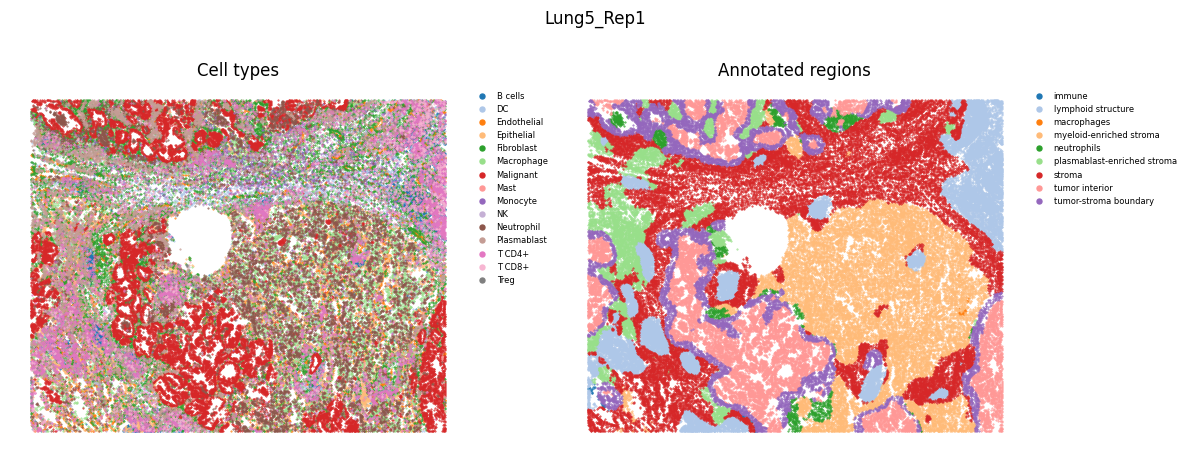

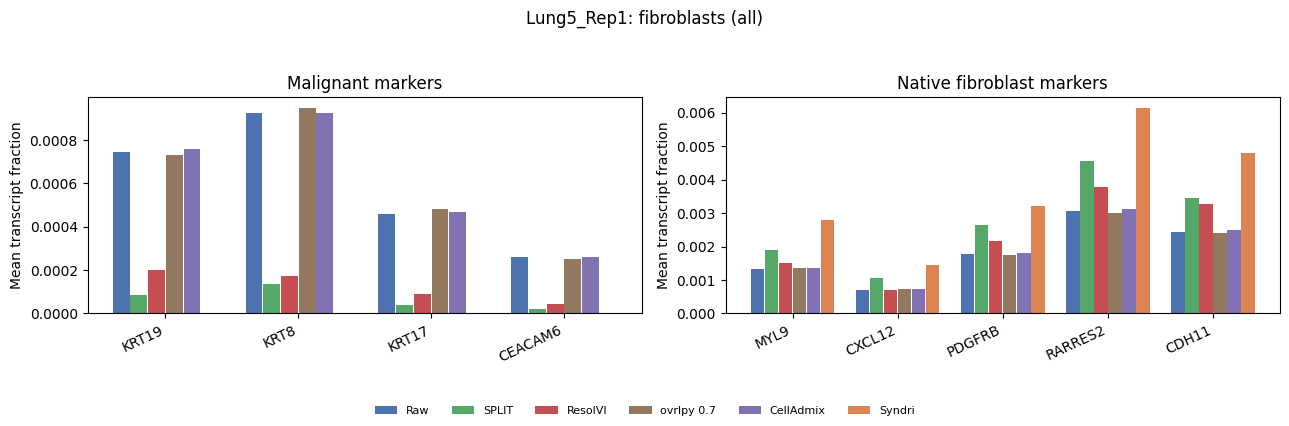

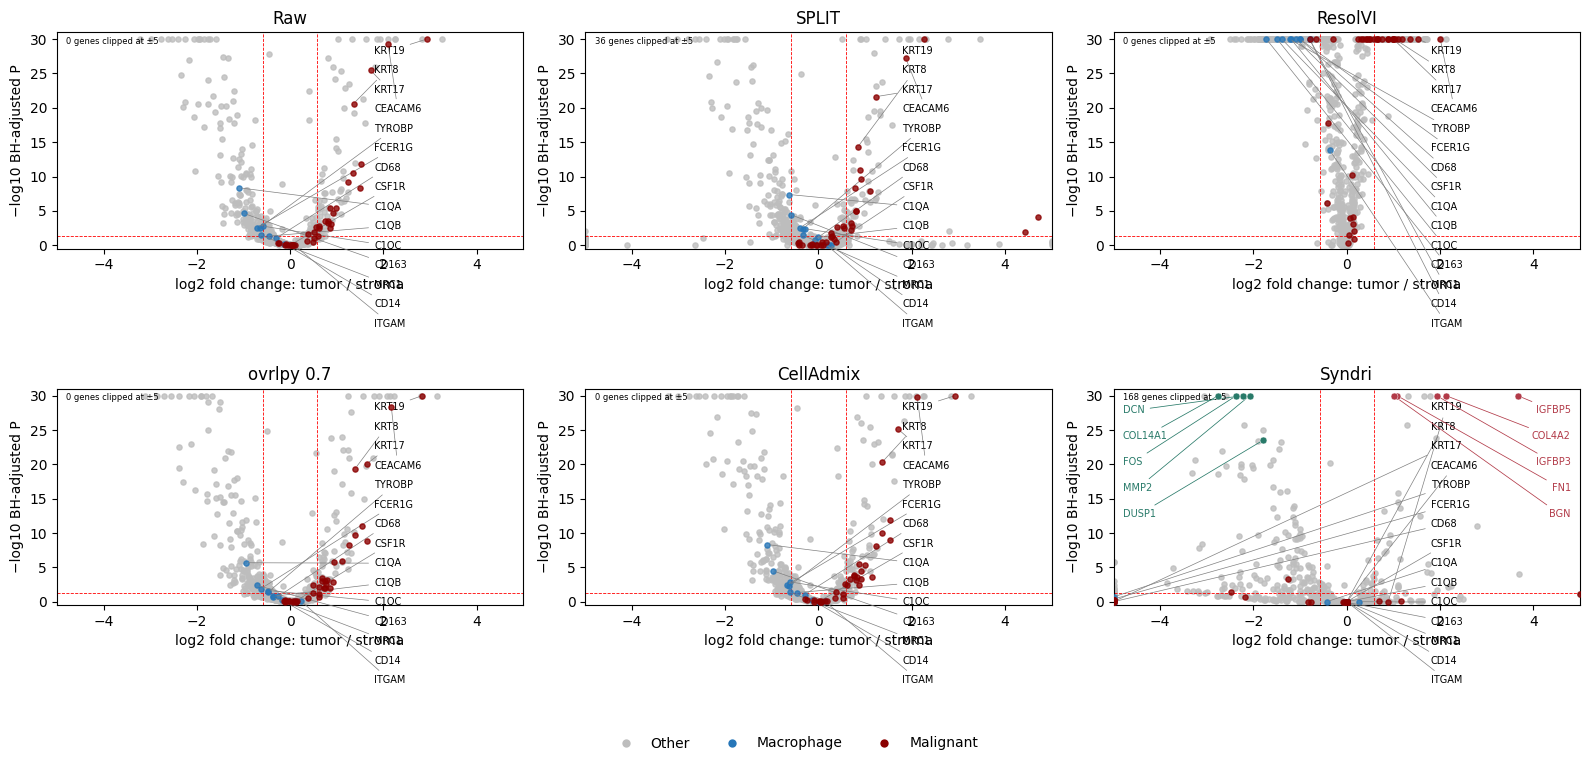

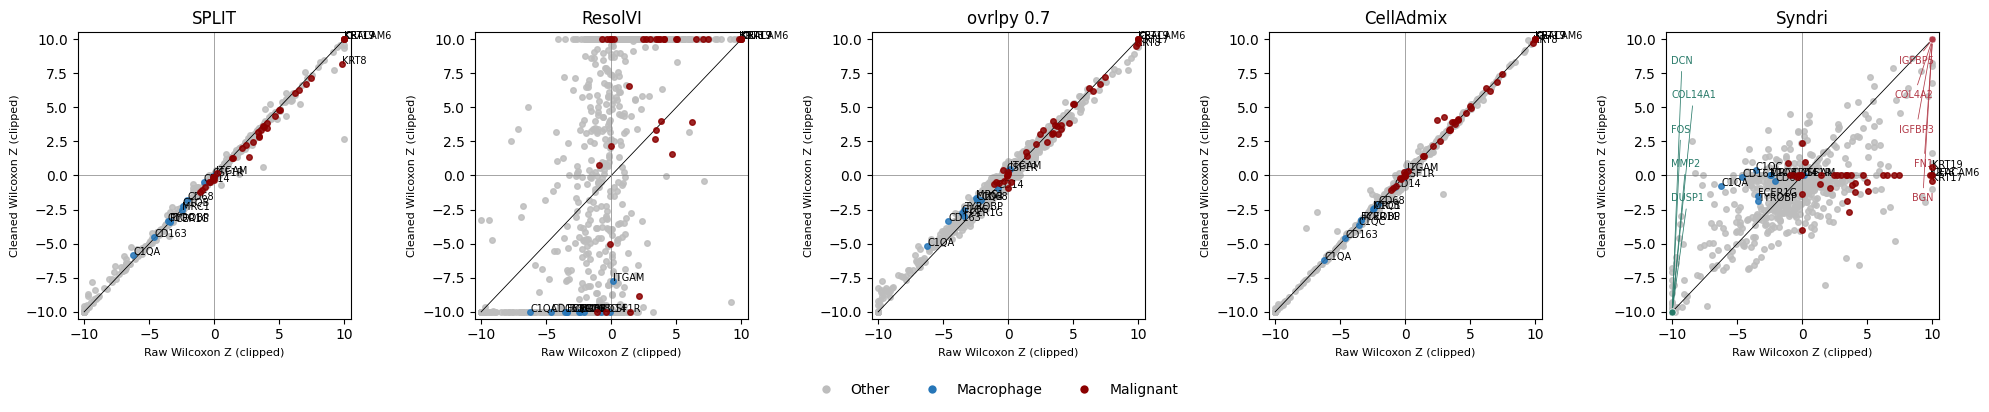

In [30]:
from matplotlib.lines import Line2D

MARKER_OTHER_COLOR = "#bdbdbd"
MARKER_MACROPHAGE_COLOR = "#2676b8"
MARKER_MALIGNANT_COLOR = "#8b0000"
MARKER_LEGEND = [
    Line2D([0],[0],marker="o",linestyle="",markerfacecolor=MARKER_OTHER_COLOR,markeredgecolor="none",label="Other",markersize=6),
    Line2D([0],[0],marker="o",linestyle="",markerfacecolor=MARKER_MACROPHAGE_COLOR,markeredgecolor="none",label="Macrophage",markersize=6),
    Line2D([0],[0],marker="o",linestyle="",markerfacecolor=MARKER_MALIGNANT_COLOR,markeredgecolor="none",label="Malignant",markersize=6),
]


def annotate_fibroblast_genes(ax, points, x_col, y_col, *, clip_x=None, clip_y=None,
                              fontsize=7, genes_to_annotate=None):
    """Label tumor-region markers on the right and stromal markers on the left."""
    if points.empty:
        return
    annotation_groups = [
        (TUMOR_REGION_FIBROBLAST_MARKERS, FIBROBLAST_TUMOR_COLOR, .98, 'right'),
        (STROMAL_FIBROBLAST_MARKERS, FIBROBLAST_STROMAL_COLOR, .02, 'left'),
    ]
    allowed_genes = None if genes_to_annotate is None else set(genes_to_annotate)
    for genes, color, label_x, ha in annotation_groups:
        if allowed_genes is not None:
            genes = [gene for gene in genes if gene in allowed_genes]
        for label_index, gene in enumerate(genes):
            row = points.loc[points['names'].eq(gene)]
            if row.empty:
                continue
            row = row.iloc[0]
            x = float(row[x_col])
            y = float(row[y_col])
            if not np.isfinite(x) or not np.isfinite(y):
                continue
            if clip_x is not None:
                x = float(np.clip(x, *clip_x))
            if clip_y is not None:
                y = float(np.clip(y, *clip_y))
            label_y = .9 - .12 * label_index
            ax.scatter([x], [y], s=25, c=[color], edgecolor='white', linewidth=.35, zorder=7)
            ax.annotate(
                gene, (x, y), xytext=(label_x, label_y), textcoords='axes fraction',
                ha=ha, va='center', fontsize=fontsize, color=color,
                arrowprops={'arrowstyle': '-', 'color': color, 'lw': .55},
                annotation_clip=False,
            )

def volcano_panels(slice_name,de_data=None):
    fig,axes=plt.subplots(2,3,figsize=(16,8),squeeze=False)
    de_data=de if de_data is None else de_data
    data=de_data[de_data['slice'].eq(slice_name)]
    finite=data.logfoldchanges.replace([np.inf,-np.inf],np.nan).dropna() if len(data) else pd.Series(dtype=float)
    bound=VOLCANO_X_LIMIT
    for ax,method in zip(axes.flat,METHODS):
        d=data[data.method.eq(method)]
        if d.empty:missing(ax,'Missing / insufficient cells');ax.set_title(method);continue
        is_malignant=d.names.isin(TUMOR_MARKERS)
        is_macrophage=d.names.isin(MACROPHAGE_MARKERS) & ~is_malignant
        is_other=~(is_malignant | is_macrophage)
        # Draw background first so both marker classes remain visible.
        for mask,color,zorder in [(is_other,MARKER_OTHER_COLOR,1),(is_macrophage,MARKER_MACROPHAGE_COLOR,3),(is_malignant,MARKER_MALIGNANT_COLOR,4)]:
            q=d.loc[mask]
            ax.scatter(q.logfoldchanges.clip(-bound,bound),-np.log10(q.pvals_adj.clip(lower=1e-30)),s=14,c=color,alpha=.8,zorder=zorder)
        for j,gene in enumerate(ADMIX_MARKERS + MACROPHAGE_MARKERS):
            q=d[d.names.eq(gene)]
            if len(q):
                xy=(float(np.clip(q.logfoldchanges.iloc[0],-bound,bound)),float(-np.log10(max(q.pvals_adj.iloc[0],1e-30))))
                ax.annotate(gene,xy,xytext=(.68,.90-.09*j),textcoords='axes fraction',fontsize=7,
                            arrowprops={'arrowstyle':'-','color':'gray','lw':.5})
        if method == 'Syndri':
            annotation_points = d[['names', 'logfoldchanges', 'pvals_adj']].copy()
            annotation_points['plot_x'] = annotation_points.logfoldchanges
            annotation_points['plot_y'] = -np.log10(annotation_points.pvals_adj.clip(lower=1e-30))
            annotate_fibroblast_genes(
                ax, annotation_points, 'plot_x', 'plot_y',
                clip_x=(-bound, bound), fontsize=7,
            )
        n_clipped=int(d.logfoldchanges.abs().gt(bound).sum())
        ax.text(.02,.98,f'{n_clipped} genes clipped at ±{bound:g}',transform=ax.transAxes,va='top',fontsize=6)
        for x in [-np.log2(1.5),np.log2(1.5)]:ax.axvline(x,color='red',ls='--',lw=.6)
        ax.axhline(-np.log10(.05),color='red',ls='--',lw=.6)
        ax.set(xlim=(-bound,bound),ylim=(-.5,31),title=method,xlabel='log2 fold change: tumor / stroma',ylabel='−log10 BH-adjusted P')
        ax.tick_params(axis='both', labelsize=8)
        ax.set_xlabel('log2 fold change: tumor / stroma', fontsize=8)
        ax.set_ylabel('−log10 BH-adjusted P', fontsize=8)
    for ax in list(axes.flat)[len(METHODS):]:ax.remove()
    # fig.suptitle(slice_name.removeprefix('st_integrated_slice-')+': fibroblast DE',y=.99)
    fig.legend(handles=MARKER_LEGEND,loc='center left',ncol=1,frameon=False,
               bbox_to_anchor=(1.01,.5),fontsize=8)
    fig.tight_layout(rect=(0,0,.86,1));return fig


def de_comparison_panels(slice_name,de_data=None):
    methods=[m for m in METHODS if m!='Raw']
    fig,axes=plt.subplots(1,5,figsize=(20,4.5),squeeze=False)
    de_data=de if de_data is None else de_data
    data=de_data[de_data['slice'].eq(slice_name)]
    raw=data[data.method.eq('Raw')].set_index('names')
    for ax,method in zip(axes.flat,methods):
        clean=data[data.method.eq(method)].set_index('names')
        if raw.empty or clean.empty:missing(ax,'Missing / insufficient cells');ax.set_title(method);continue
        joined=raw[['scores']].join(clean[['scores']],lsuffix='_raw',rsuffix='_clean',how='inner')
        is_malignant=joined.index.isin(TUMOR_MARKERS)
        is_macrophage=joined.index.isin(MACROPHAGE_MARKERS) & ~is_malignant
        is_other=~(is_malignant | is_macrophage)
        # Malignant red points are drawn last with the highest z-order.
        for mask,color,zorder in [(is_other,MARKER_OTHER_COLOR,1),(is_macrophage,MARKER_MACROPHAGE_COLOR,3),(is_malignant,MARKER_MALIGNANT_COLOR,4)]:
            q=joined.loc[mask]
            ax.scatter(q.scores_raw.clip(-10,10),q.scores_clean.clip(-10,10),s=16,c=color,alpha=.85,zorder=zorder)
        for gene in ADMIX_MARKERS + MACROPHAGE_MARKERS:
            if gene in joined.index:
                r=joined.loc[gene];ax.annotate(gene,(np.clip(r.scores_raw,-10,10),np.clip(r.scores_clean,-10,10)),fontsize=7)
        if method == 'Syndri':
            annotation_points = joined.reset_index().rename(columns={'index': 'names'})
            annotate_fibroblast_genes(
                ax, annotation_points, 'scores_raw', 'scores_clean',
                clip_x=(-10, 10), clip_y=(-10, 10), fontsize=7,
            )
        ax.plot([-10,10],[-10,10],color='black',lw=.6);ax.axhline(0,color='gray',lw=.5);ax.axvline(0,color='gray',lw=.5)
        ax.set(xlim=(-10.5,10.5),ylim=(-10.5,10.5),title=method,xlabel='Raw Wilcoxon Z (clipped)',ylabel='Cleaned Wilcoxon Z (clipped)')
        ax.tick_params(axis='both', labelsize=8)
        ax.set_ylabel(ax.get_ylabel(), fontsize=8)
        ax.set_xlabel(ax.get_xlabel(), fontsize=8)
    # No repeated marker legend on the Z-score comparison panels.
    fig.tight_layout(rect=(0,0,1,1));return fig


for path in paths:
    for label,plot in [('tissue',lambda p=path:tissue_maps(p)),
                       ('expression',lambda p=path:expression_panels(p.stem)),
                       ('volcano',lambda p=path:volcano_panels(p.stem)),
                       ('de_comparison',lambda p=path:de_comparison_panels(p.stem))]:
        fig=plot();save_figure(fig,path.stem+'_'+label)
        if path.stem==PLOT_SLICE:plt.show()
        plt.close(fig)


## ResolVI-native Bayesian volcano (saved model; authors' settings)

Uses `PLOT_SLICE` and the same shared fibroblast cohort as the Wilcoxon panels, comparing tumor interior against stroma. Loads the existing slice-specific checkpoint; no refitting is performed.

DE options match `resolvi-reproducibility/figure4_nanostring_with_outputs.ipynb`, cell 72: `weights='importance'`, `pseudocounts=1e-3`, `delta=0.05`, `filter_outlier_cells=True`, `mode='change'`, and `test_mode='three'`. Outlier filtering can exclude cells from the starting shared cohort. The authors compared anti-/pro-inflammatory tumor niches; this notebook retains its tumor/stroma fibroblast contrast.

Display settings match their cell 74: posterior non-DE probability <0.1, absolute mean log2 fold change >0.4, top 30 qualifying gene labels, and a 10×10-inch figure. Red denotes higher expression in tumor-region fibroblasts; blue denotes higher expression in stroma. Highlighting uses these probability/effect thresholds, not the separate 5% posterior-FDR result column. The y-axis is explicitly labeled **−log10 posterior non-DE probability**, reflecting the `proba_not_de` column passed to the authors' plotting function. Zero probabilities are capped at 1e−12 for display.

Results are cached by checkpoint, cohort, helper code and DE settings. Existing outputs are preserved.


In [7]:
import subprocess
RESOLVI_PYTHON = Path('/home/jwinchel/.venv/resolvi/bin/python')
# Match figure4_nanostring_with_outputs.ipynb, cells 72 and 74.
NATIVE_DELTA = 0.05
NATIVE_WEIGHTS = 'importance'
NATIVE_PSEUDOCOUNTS = 1e-3
NATIVE_FILTER_OUTLIERS = True
NATIVE_TEST_MODE = 'three'
NATIVE_SIGN_THRESHOLD = 0.1
NATIVE_LFC_THRESHOLD = 0.4
NATIVE_TOP_GENES = 30
NATIVE_FDR = 0.05
native_source = ROOT/'final'/f'{PLOT_SLICE}.h5ad'
cohort_record = json.loads((RUN_DIR/PLOT_SLICE/'complete.json').read_text())
native_cohort = Path(cohort_record['attempt'])/'cells.csv'
original_export = ROOT/'competitors/resolvi'/f'{PLOT_SLICE}.h5ad'
with h5py.File(original_export,'r') as f:
    original_settings = ad.io.read_elem(f['uns']['resolvi_competitor'])
if 'model_dir' not in original_settings:
    raise FileNotFoundError(f'No saved-model path recorded in {original_export}')
native_model_dir = Path(original_settings['model_dir'])
if native_model_dir.name != PLOT_SLICE:
    raise ValueError(f'Saved model does not match PLOT_SLICE: {native_model_dir}')
for filename in ['model.pt', 'adata.h5ad']:
    if not (native_model_dir/filename).is_file():
        raise FileNotFoundError(native_model_dir/filename)
native_script = PROJECT/'scripts/competitors/resolvi_native_cosmx_de.py'
native_config = dict(final=str(native_source),cohort=str(native_cohort),model_dir=str(native_model_dir),
    source_signature=file_signature(native_source),
    model_signatures=[file_signature(native_model_dir/f) for f in ['model.pt','adata.h5ad']],
    cohort_sha256=hashlib.sha256(native_cohort.read_bytes()).hexdigest(),
    script_sha256=hashlib.sha256(native_script.read_bytes()).hexdigest(),
    delta=NATIVE_DELTA,fdr=NATIVE_FDR,weights=NATIVE_WEIGHTS,
    pseudocounts=NATIVE_PSEUDOCOUNTS,filter_outlier_cells=NATIVE_FILTER_OUTLIERS,
    test_mode=NATIVE_TEST_MODE,
    min_group_size=MIN_GROUP_SIZE,seed=0,scvi_version='1.3.3',refit=False)
native_key=hashlib.sha256(json.dumps(native_config,sort_keys=True).encode()).hexdigest()[:16]
native_root=RUN_DIR/'resolvi_native'/PLOT_SLICE/native_key
native_root.mkdir(parents=True,exist_ok=True)
completed=sorted(p for p in native_root.glob('attempt_*') if (p/'complete.json').exists())
if completed:
    native_out=completed[-1]
else:
    number=1
    while (native_root/f'attempt_{number}').exists():number+=1
    native_out=native_root/f'attempt_{number}'
    native_out.mkdir()
    request=native_out/'request.json'
    request.write_text(json.dumps(native_config,indent=2))
    print('Loading saved ResolVI model and computing native DE; log:',native_out/'run.log',flush=True)
    with (native_out/'run.log').open('x') as log:
        subprocess.run([str(RESOLVI_PYTHON),'-u',str(native_script),str(request)],
                       stdout=log,stderr=subprocess.STDOUT,check=True)
native_de=pd.read_csv(native_out/'de.csv',index_col='feature_id')
_,native_var=read_metadata(native_source)
native_de['gene']=resolved_gene_symbols(native_var).reindex(native_de.index).to_numpy()
native_de['malignant_marker']=native_de.gene.isin(TUMOR_MARKERS)
fdr_column=f'is_de_fdr_{NATIVE_FDR}'
assert {'lfc_mean','proba_de',fdr_column} <= set(native_de.columns)
# The authors pass proba_not_de to a generic volcano function; retain an explicit Bayesian axis label.
native_de['posterior_non_de'] = native_de['proba_not_de'] if 'proba_not_de' in native_de else 1-native_de.proba_de
native_de['plot_y'] = -np.log10(native_de.posterior_non_de.clip(lower=1e-12,upper=1))
native_de['highlight'] = np.select([
    native_de.posterior_non_de.lt(NATIVE_SIGN_THRESHOLD) & native_de.lfc_mean.gt(NATIVE_LFC_THRESHOLD),
    native_de.posterior_non_de.lt(NATIVE_SIGN_THRESHOLD) & native_de.lfc_mean.lt(-NATIVE_LFC_THRESHOLD),
], ['Higher in tumor', 'Higher in stroma'], default='Below display thresholds')
fig,ax=plt.subplots(figsize=(10,10))
for category,color in [('Below display thresholds','gray'),('Higher in tumor','#D62728'),('Higher in stroma','#1F77B4')]:
    q=native_de.loc[native_de.highlight.eq(category)]
    ax.scatter(q.lfc_mean,q.plot_y,c=color,s=18,alpha=.75,label=category)
# Label the top 30 genes passing both display thresholds, ranked by non-DE probability.
label_genes = (native_de.loc[native_de.highlight.ne('Below display thresholds')]
               .sort_values('posterior_non_de').head(NATIVE_TOP_GENES))
for _,r in label_genes.iterrows():
    ax.annotate(r.gene,(r.lfc_mean,r.plot_y),xytext=(3,3),textcoords='offset points',fontsize=8)
for x in [-NATIVE_LFC_THRESHOLD,NATIVE_LFC_THRESHOLD]:ax.axvline(x,color='black',ls='--',lw=.6)
ax.axhline(-np.log10(NATIVE_SIGN_THRESHOLD),color='black',ls='--',lw=.6)
ax.set(xlabel='Posterior mean log2 fold change: tumor / stroma',
       ylabel='−log10 posterior probability of non-DE',
       title=PLOT_SLICE.removeprefix('st_integrated_slice-')+': ResolVI-native DE (authors’ settings)')
ax.legend(fontsize=8,frameon=False);fig.tight_layout()
save_figure(fig,PLOT_SLICE+'_resolvi_native_volcano_authors_settings');plt.show()
print('Author-matched display calls:', native_de.highlight.value_counts().to_dict())
print('Native DE results:',native_out)
print('Existing model used:',native_model_dir)


Loading saved ResolVI model and computing native DE; log: /home/jwinchel/Syndri/figures/outputs/cosmx_fibroblast_tutorial/f10ec16a1469b24b/resolvi_native/st_integrated_slice-Lung5_Rep1/f857ad6eccb220fc/attempt_1/run.log


KeyboardInterrupt: 

## Across-slice summary
Each point is one slice, using that slice's shared fibroblast cohort. Lines connect the same slice across methods. Compare malignant-marker burden with native-marker preservation; reduced malignant signal accompanied by a large loss of native expression is not automatically a better correction. The two expression measures help distinguish compositional enrichment from increases in absolute estimated expression.

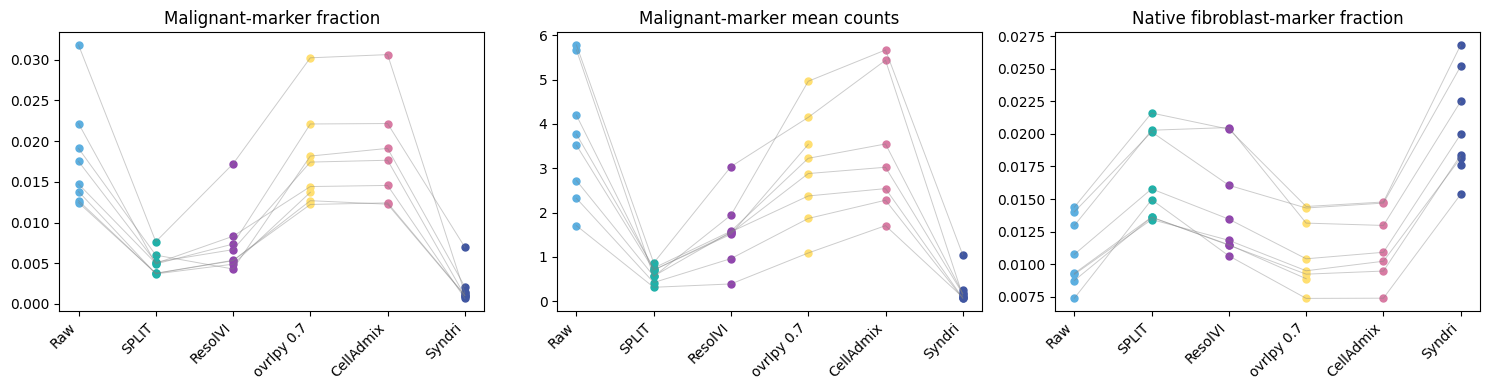

method,Raw,SPLIT,ResolVI,ovrlpy 0.7,CellAdmix,Syndri
sample,,,,,,
Lung12,4.0,4.0,23.0,4.0,4.0,0.0
Lung13,9.0,9.0,19.0,9.0,9.0,0.0
Lung5_Rep1,19.0,15.0,16.0,20.0,20.0,0.0
Lung5_Rep2,19.0,13.0,25.0,19.0,NaN,0.0
Lung5_Rep3,18.0,18.0,14.0,15.0,20.0,0.0
Lung6,7.0,7.0,12.0,5.0,7.0,0.0
Lung9_Rep1,4.0,4.0,10.0,8.0,4.0,0.0
Lung9_Rep2,2.0,2.0,8.0,2.0,2.0,0.0


Saved tables and figures: /home/jwinchel/Syndri/figures/outputs/cosmx_fibroblast_tutorial/f10ec16a1469b24b


In [8]:
fig,axes=plt.subplots(1,3,figsize=(15,4))
all_cells=burden[burden.region.eq('all')]
for ax,metric,title in zip(axes,['malignant_mean_fraction','malignant_mean_counts','native_mean_fraction'],
                         ['Malignant-marker fraction','Malignant-marker mean counts','Native fibroblast-marker fraction']):
    for sample,d in all_cells.groupby('sample',sort=False):
        series=d.set_index('method')[metric].reindex(METHODS)
        ax.plot(range(len(METHODS)),series,color='gray',alpha=.4,lw=.7)
        for i,method in enumerate(METHODS):
            if pd.notna(series[method]):ax.scatter(i,series[method],color=COLORS[method],s=25)
    ax.set_xticks(range(len(METHODS)),METHODS,rotation=45,ha='right');ax.set_title(title)
fig.tight_layout();save_figure(fig,'cross_slice_summary');plt.show()

summary=de.copy()
if len(summary):
    summary['significant_tumor_up']=summary.malignant_marker & summary.pvals_adj.lt(.05) & summary.logfoldchanges.gt(np.log2(1.5))
    summary=summary.groupby(['sample','method'],sort=False).significant_tumor_up.sum().unstack().reindex(columns=METHODS)
    display(summary)
for name,frame in [('de',de),('expression',expression),('burden',burden),('status',status),('marker_coverage',marker_coverage)]:
    if not (RUN_DIR/f'{name}.csv').exists():frame.to_csv(RUN_DIR/f'{name}.csv',index=False,mode='x')
print('Saved tables and figures:',RUN_DIR)


## Pooled marker-program changes relative to Raw

This single heatmap pools a predefined set of slices across all fibroblasts. Choose `POOLED_HEATMAP_METRIC` in the code cell to plot change in normalized transcript proportion, change in absolute marker counts per fibroblast, or the fraction of Raw marker counts removed. All values use the same slices available for each method. Raw is omitted from the heatmap.

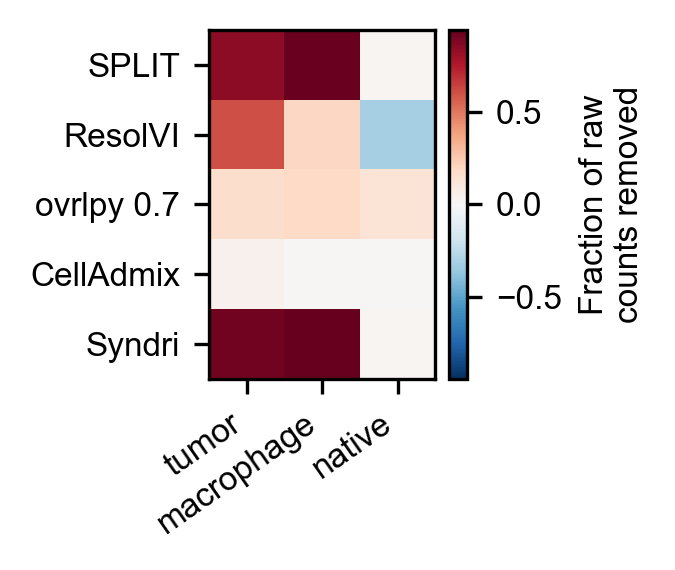

,method,n_requested_slices,n_matched_slices,matched_slices
0,SPLIT,8,8,st_integrated_slice-Lung5_Rep1;st_integrated_s...
1,ResolVI,8,8,st_integrated_slice-Lung5_Rep1;st_integrated_s...
2,ovrlpy 0.7,8,8,st_integrated_slice-Lung5_Rep1;st_integrated_s...
3,CellAdmix,8,7,st_integrated_slice-Lung5_Rep1;st_integrated_s...
4,Syndri,8,8,st_integrated_slice-Lung5_Rep1;st_integrated_s...


,method,marker_category,normalized_transcript_proportion,raw_proportion_matched_slices,delta_proportion,delta_percentage_points,absolute_marker_counts_per_cell,raw_absolute_marker_counts_per_cell,delta_absolute_counts_per_cell,fraction_original_counts_removed,n_matched_slices,matched_slices
0,SPLIT,tumor,0.004058,0.016169,-0.012112,-1.211192,0.615156,3.930234,-3.315077,0.843481,8,st_integrated_slice-Lung5_Rep1;st_integrated_s...
1,SPLIT,macrophage,0.000684,0.006608,-0.005924,-0.592400,0.103706,1.606187,-1.502480,0.935433,8,st_integrated_slice-Lung5_Rep1;st_integrated_s...
2,SPLIT,native,0.015019,0.009566,0.005453,0.545297,2.277082,2.325266,-0.048185,0.020722,8,st_integrated_slice-Lung5_Rep1;st_integrated_s...
3,ResolVI,tumor,0.006375,0.016169,-0.009794,-0.979400,1.544328,3.930234,-2.385906,0.607065,8,st_integrated_slice-Lung5_Rep1;st_integrated_s...
4,ResolVI,macrophage,0.005323,0.006608,-0.001285,-0.128504,1.289394,1.606187,-0.316793,0.197233,8,st_integrated_slice-Lung5_Rep1;st_integrated_s...
5,ResolVI,native,0.012639,0.009566,0.003073,0.307284,3.061621,2.325266,0.736354,-0.316675,8,st_integrated_slice-Lung5_Rep1;st_integrated_s...
6,ovrlpy 0.7,tumor,0.015749,0.016169,-0.000421,-0.042087,3.279462,3.930234,-0.650771,0.165581,8,st_integrated_slice-Lung5_Rep1;st_integrated_s...
7,ovrlpy 0.7,macrophage,0.006276,0.006608,-0.000332,-0.033158,1.307003,1.606187,-0.299184,0.186269,8,st_integrated_slice-Lung5_Rep1;st_integrated_s...
8,ovrlpy 0.7,native,0.009711,0.009566,0.000145,0.014487,2.022266,2.325266,-0.303001,0.130308,8,st_integrated_slice-Lung5_Rep1;st_integrated_s...
9,CellAdmix,tumor,0.016825,0.016872,-0.000047,-0.004686,3.714829,3.881197,-0.166368,0.042865,7,st_integrated_slice-Lung5_Rep1;st_integrated_s...


Saved pooled marker-program deltas: /home/jwinchel/Syndri/figures/outputs/cosmx_fibroblast_tutorial/f10ec16a1469b24b/pooled_marker_program_delta.csv


In [42]:
from matplotlib.colors import TwoSlopeNorm

# Edit this list to pool a different predefined slice set.
POOLED_HEATMAP_SLICES = [
    'st_integrated_slice-Lung5_Rep1',
    'st_integrated_slice-Lung5_Rep2',
    'st_integrated_slice-Lung5_Rep3',
    'st_integrated_slice-Lung12',
    'st_integrated_slice-Lung13',
    'st_integrated_slice-Lung6',
    'st_integrated_slice-Lung9_Rep1',
    'st_integrated_slice-Lung9_Rep2',
]
MARKER_PROGRAMS = {
    'tumor': TUMOR_MARKERS,
    'macrophage': MACROPHAGE_MARKERS,
    'native': NATIVE_MARKERS,
}
PROGRAM_ORDER = ['tumor', 'macrophage', 'native']
HEATMAP_METHODS = [method for method in METHODS if method != 'Raw']
# Options: 'normalized_proportion', 'absolute_counts_per_cell', or 'fraction_original_counts_removed'.
POOLED_HEATMAP_METRIC = 'fraction_original_counts_removed'

# Weight per-cell means by the number of cells so pooling corresponds to pooled
# transcript counts across slices. Each method is compared with Raw on matched slices.
all_expression = expression.loc[
    expression.region.eq('all') & expression['slice'].isin(POOLED_HEATMAP_SLICES)
].copy()
cell_counts = burden.loc[
    burden.region.eq('all') & burden['slice'].isin(POOLED_HEATMAP_SLICES),
    ['slice', 'method', 'n_cells'],
]
weighted_expression = all_expression.merge(
    cell_counts, on=['slice', 'method'], how='left', validate='many_to_one'
)
if weighted_expression.n_cells.isna().any():
    raise ValueError('Missing shared-cohort cell counts for pooled marker summaries.')
weighted_expression['pooled_counts'] = weighted_expression.mean_counts * weighted_expression.n_cells
raw_slices_available = set(
    weighted_expression.loc[weighted_expression.method.eq('Raw'), 'slice']
)

pooled_rows = []
coverage_rows = []
for method in HEATMAP_METHODS:
    method_slices = set(weighted_expression.loc[weighted_expression.method.eq(method), 'slice'])
    matched_slices = [
        slice_name for slice_name in POOLED_HEATMAP_SLICES
        if slice_name in method_slices and slice_name in raw_slices_available
    ]
    coverage_rows.append({
        'method': method,
        'n_requested_slices': len(POOLED_HEATMAP_SLICES),
        'n_matched_slices': len(matched_slices),
        'matched_slices': ';'.join(matched_slices),
    })
    method_data = weighted_expression.loc[
        weighted_expression.method.eq(method) & weighted_expression['slice'].isin(matched_slices)
    ]
    raw_data = weighted_expression.loc[
        weighted_expression.method.eq('Raw') & weighted_expression['slice'].isin(matched_slices)
    ]
    for category, genes in MARKER_PROGRAMS.items():
        method_total = float(method_data.pooled_counts.sum())
        raw_total = float(raw_data.pooled_counts.sum())
        method_proportion = (
            float(method_data.loc[method_data.gene.isin(genes), 'pooled_counts'].sum()) / method_total
            if method_total > 0 else np.nan
        )
        raw_proportion = (
            float(raw_data.loc[raw_data.gene.isin(genes), 'pooled_counts'].sum()) / raw_total
            if raw_total > 0 else np.nan
        )
        method_cells = float(method_data.groupby('slice').n_cells.first().sum())
        raw_cells = float(raw_data.groupby('slice').n_cells.first().sum())
        method_absolute = (
            float(method_data.loc[method_data.gene.isin(genes), 'pooled_counts'].sum()) / method_cells
            if method_cells > 0 else np.nan
        )
        raw_absolute = (
            float(raw_data.loc[raw_data.gene.isin(genes), 'pooled_counts'].sum()) / raw_cells
            if raw_cells > 0 else np.nan
        )
        method_marker_total = float(method_data.loc[method_data.gene.isin(genes), 'pooled_counts'].sum())
        raw_marker_total = float(raw_data.loc[raw_data.gene.isin(genes), 'pooled_counts'].sum())
        fraction_removed = (1 - method_marker_total / raw_marker_total) if raw_marker_total > 0 else np.nan
        delta = method_proportion - raw_proportion
        pooled_rows.append({
            'method': method,
            'marker_category': category,
            'normalized_transcript_proportion': method_proportion,
            'raw_proportion_matched_slices': raw_proportion,
            'delta_proportion': delta,
            'delta_percentage_points': 100 * delta,
            'absolute_marker_counts_per_cell': method_absolute,
            'raw_absolute_marker_counts_per_cell': raw_absolute,
            'delta_absolute_counts_per_cell': method_absolute - raw_absolute,
            'fraction_original_counts_removed': fraction_removed,
            'n_matched_slices': len(matched_slices),
            'matched_slices': ';'.join(matched_slices),
        })
pooled_marker_program_delta = pd.DataFrame(pooled_rows)

if POOLED_HEATMAP_METRIC == 'normalized_proportion':
    value_column = 'delta_percentage_points'
    colorbar_label = 'Δ normalized transcript proportion (percentage points)'
    plot_title_metric = 'normalized transcript proportion change (percentage points)'
elif POOLED_HEATMAP_METRIC == 'absolute_counts_per_cell':
    value_column = 'delta_absolute_counts_per_cell'
    colorbar_label = 'mean Δ absolute\nmarker counts'
    plot_title_metric = 'absolute marker-count change per fibroblast'
elif POOLED_HEATMAP_METRIC == 'fraction_original_counts_removed':
    value_column = 'fraction_original_counts_removed'
    colorbar_label = 'Fraction of Raw\nmarker counts removed'
    plot_title_metric = 'fraction of Raw marker counts removed'
else:
    raise ValueError(
        "POOLED_HEATMAP_METRIC must be 'normalized_proportion', 'absolute_counts_per_cell', or 'fraction_original_counts_removed'."
    )
matrix = (pooled_marker_program_delta
          .pivot(index='marker_category', columns='method', values=value_column)
          .reindex(index=PROGRAM_ORDER, columns=HEATMAP_METHODS)
          .to_numpy(dtype=float))
masked_matrix = np.ma.masked_invalid(matrix)
finite_values = matrix[np.isfinite(matrix)]
limit = float(np.max(np.abs(finite_values))) if finite_values.size else 0.0
limit = limit if limit > 0 else 1e-6
norm = TwoSlopeNorm(vmin=-limit, vcenter=0, vmax=limit)
cmap = plt.get_cmap('RdBu_r').copy()
cmap.set_bad('#eeeeee')
# fig, ax = plt.subplots(figsize=(max(9, 1.8 * len(HEATMAP_METHODS)), 3.5))
fig, ax = plt.subplots(figsize=(2.25, 2),dpi=300)
image = ax.imshow(masked_matrix.T, aspect='auto', cmap=cmap, norm=norm)
ax.set_yticks(np.arange(len(HEATMAP_METHODS)), HEATMAP_METHODS, ha='right',fontsize=8)
ax.set_xticks(np.arange(len(PROGRAM_ORDER)), PROGRAM_ORDER,fontsize=8,rotation=35,ha='right')
# ax.set_xlabel('Method')
# ax.set_ylabel('Marker category')
requested_names = [name.removeprefix('st_integrated_slice-') for name in POOLED_HEATMAP_SLICES]
# ax.set_title('Pooled all-fibroblast ' + plot_title_metric + ' vs Raw: ' + ', '.join(requested_names))
# for row in range(masked_matrix.shape[0]):
#     for col in range(masked_matrix.shape[1]):
#         value = masked_matrix[row, col]
#         label = '—' if np.ma.is_masked(value) else f'{float(value):+.2f}'
#         ax.text(col, row, label, ha='center', va='center', fontsize=9, color='black')
cbar = fig.colorbar(image, ax=ax, label=colorbar_label)
cbar.ax.tick_params(labelsize=8)
cbar.set_label('Fraction of raw\ncounts removed', size=8)
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'Figure4_heatmap.svg',bbox_inches='tight')
save_figure(fig, 'pooled_marker_program_delta_heatmap')
plt.show()

coverage = pd.DataFrame(coverage_rows)
display(coverage)
display(pooled_marker_program_delta)
pooled_delta_path = RUN_DIR / 'pooled_marker_program_delta.csv'
if not pooled_delta_path.exists():
    pooled_marker_program_delta.to_csv(pooled_delta_path, index=False, mode='x')
print('Saved pooled marker-program deltas:', pooled_delta_path)

## Pooled Lung5 replicate fibroblast analysis

Concatenate the saved shared fibroblast cohorts from **Lung5_Rep1, Lung5_Rep2 and Lung5_Rep3 only**, matching the authors’ NSCLC DE analysis, then recompute mean per-cell transcript fractions and tumor-versus-stroma Wilcoxon DE for each method. Syndri cleaning is calibrated separately within each complete slice before selecting its fibroblasts, as in the slice-specific analysis. Each cell has equal weight, so larger slices contribute more.

Methods missing a corrected matrix for a slice use only their available slices; coverage and cell counts are reported explicitly. For Raw-versus-cleaned DE-score comparisons, Raw is recomputed on the **same slices and cells as that method**. Set `POOLED_REQUIRE_COMPLETE_METHODS=True` to omit methods without all three Lung5 replicates. Missing matrices are never replaced with Raw counts.

Pooled Wilcoxon P values do not adjust for slice/donor effects or spatial dependence. They are descriptive and should be checked against the slice-specific results. The native Bayesian volcano above remains slice-specific: independent ResolVI models cannot be passed as one fitted model to `differential_expression()`.


,method,n_slices,n_requested_slices,n_cells,slices,included
0,Raw,3,3,17999,st_integrated_slice-Lung5_Rep1;st_integrated_s...,True
1,SPLIT,3,3,17999,st_integrated_slice-Lung5_Rep1;st_integrated_s...,True
2,ResolVI,3,3,17999,st_integrated_slice-Lung5_Rep1;st_integrated_s...,True
3,ovrlpy 0.7,3,3,17999,st_integrated_slice-Lung5_Rep1;st_integrated_s...,True
4,CellAdmix,2,3,12082,st_integrated_slice-Lung5_Rep1;st_integrated_s...,True
5,Syndri,3,3,17999,st_integrated_slice-Lung5_Rep1;st_integrated_s...,True


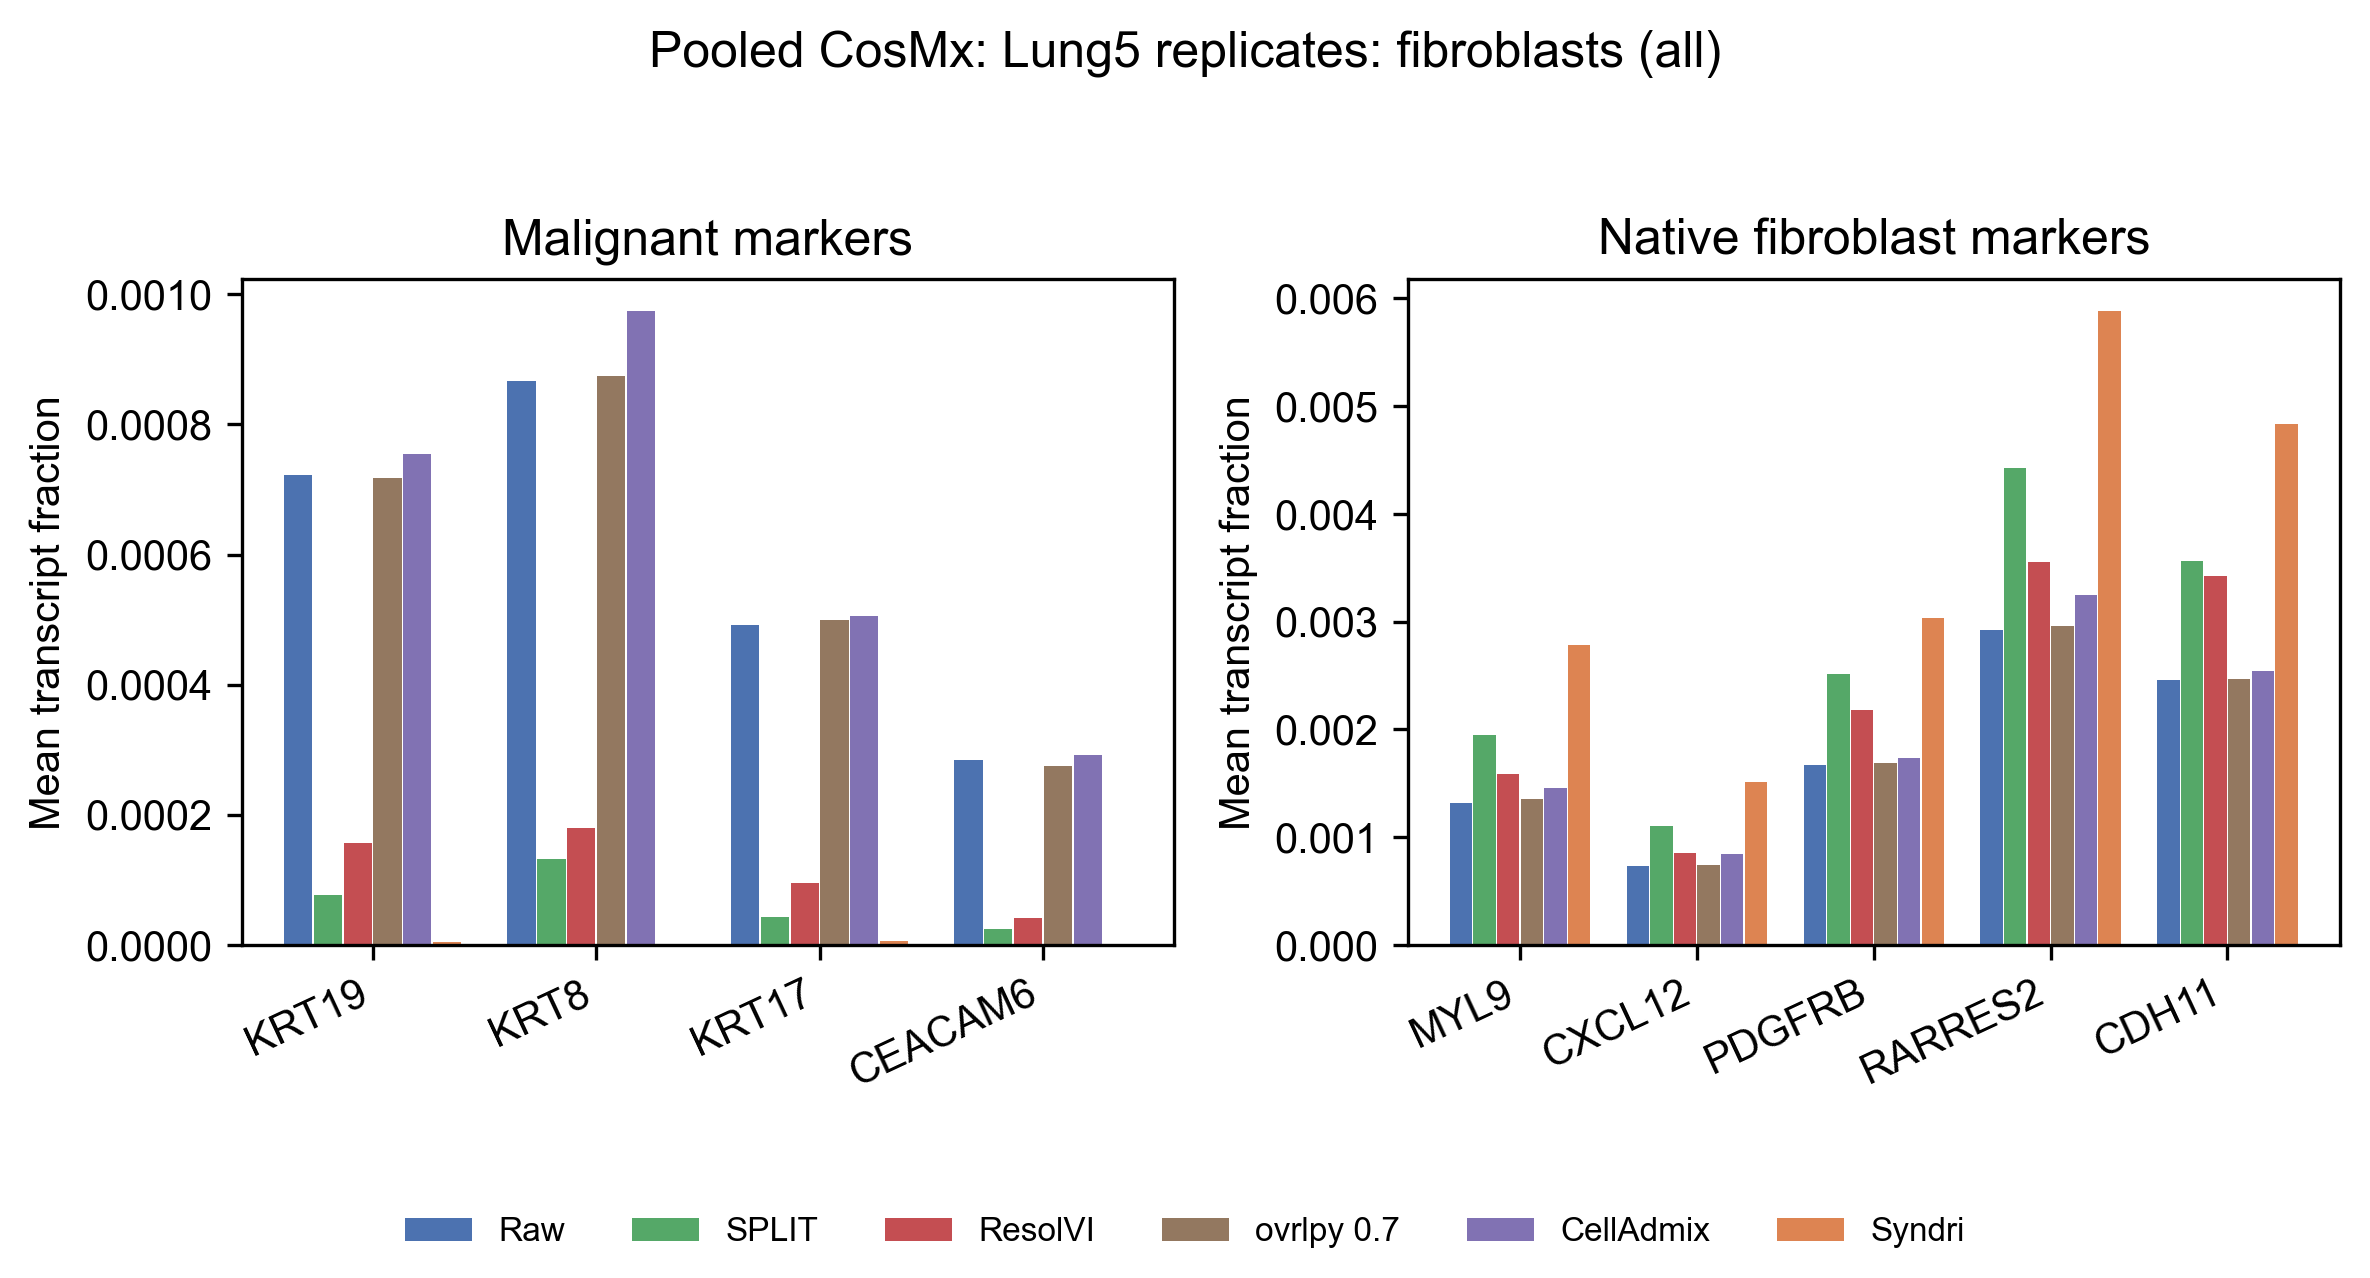

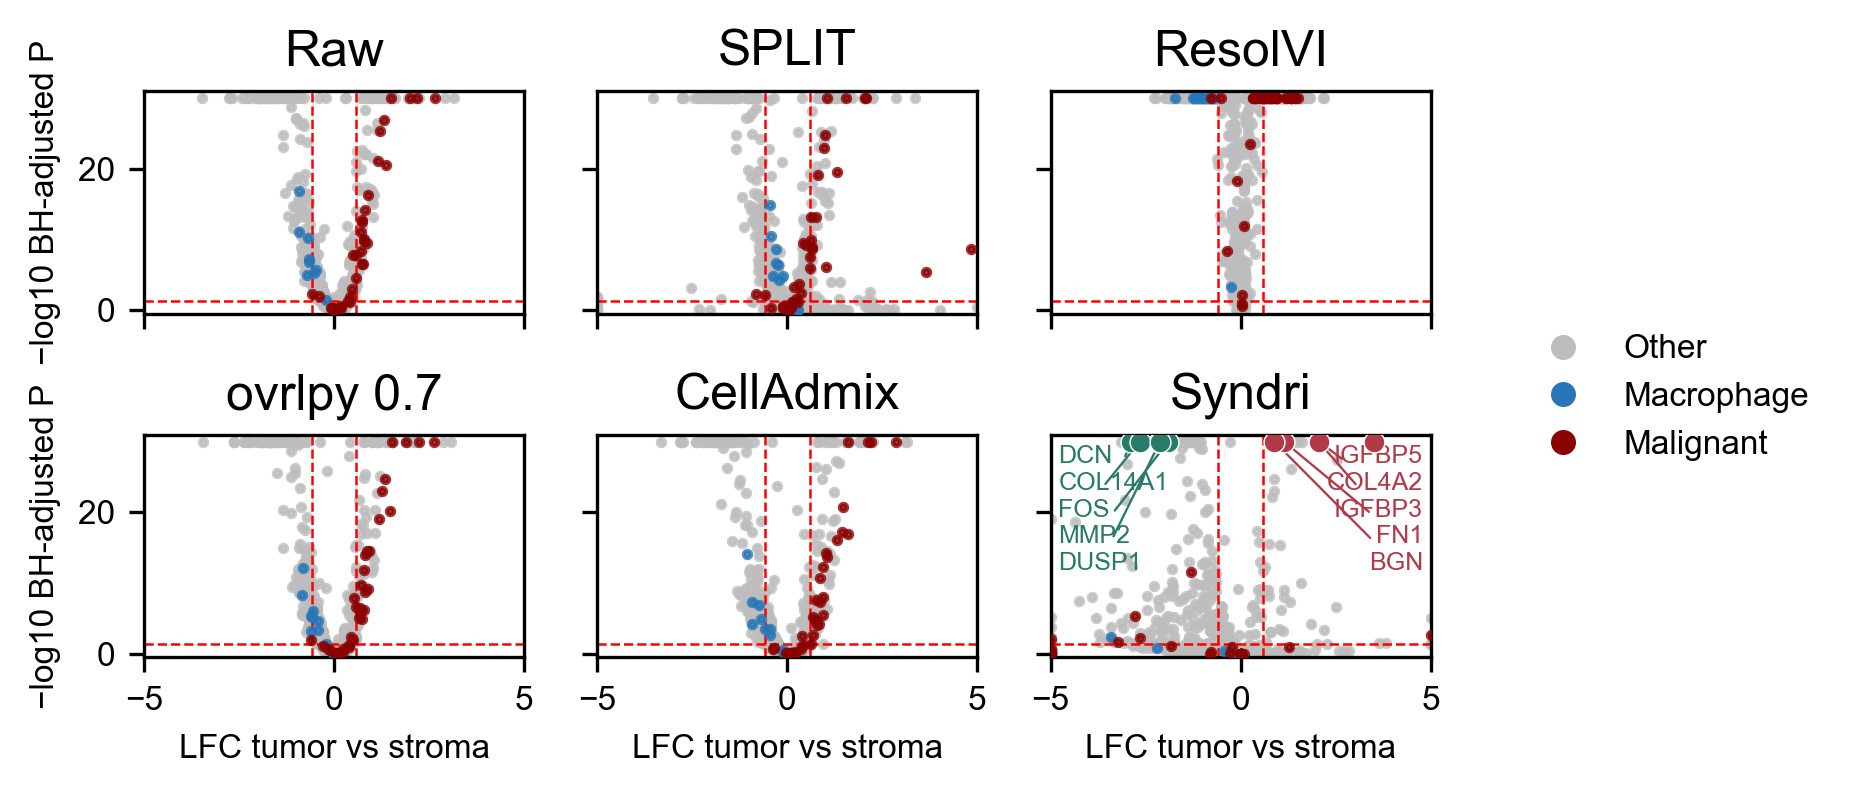

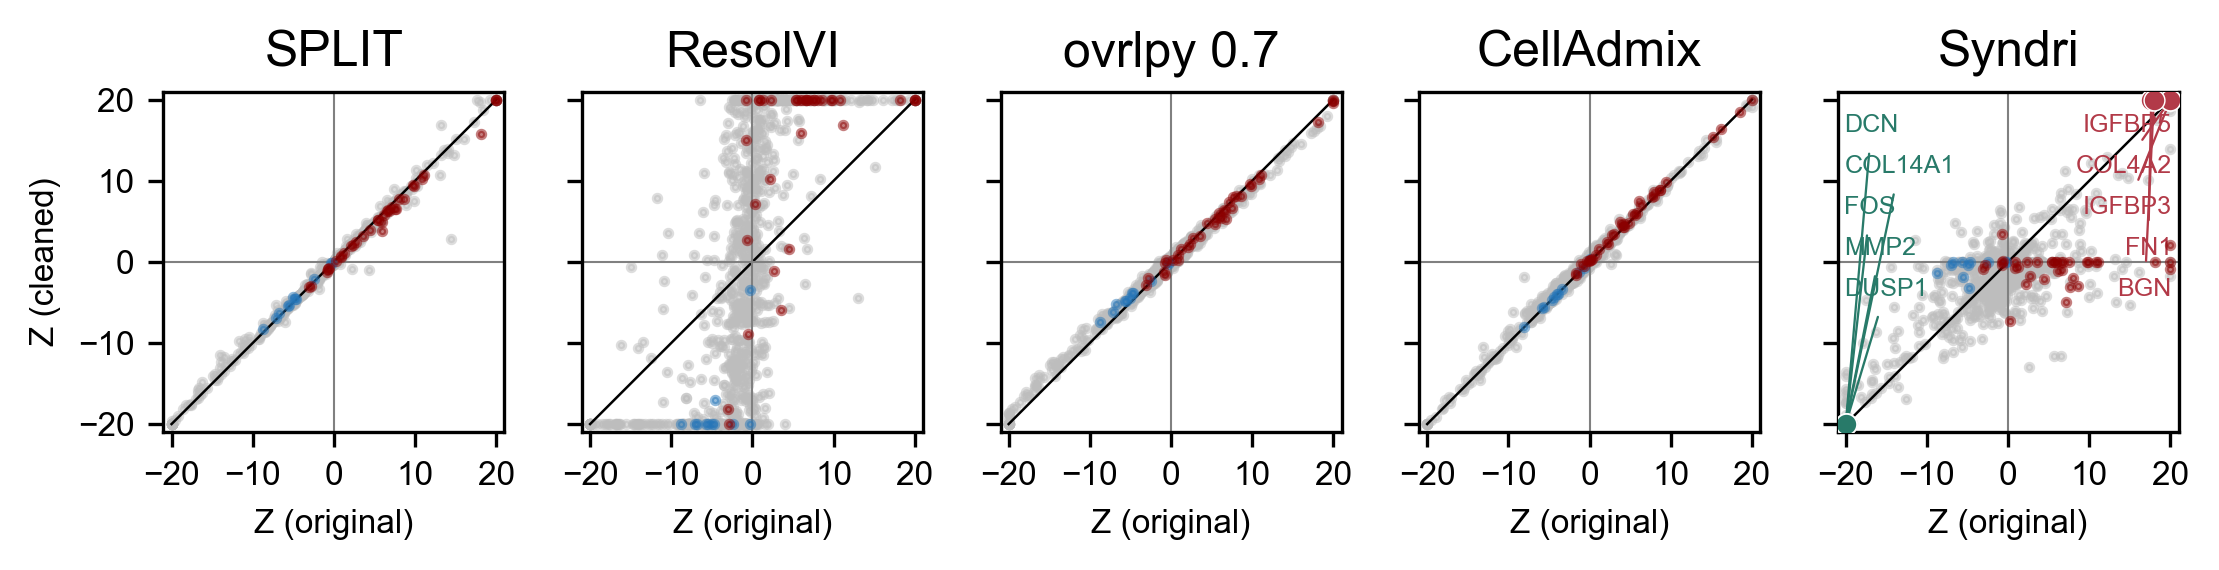

Pooled tables: /home/jwinchel/Syndri/figures/outputs/cosmx_fibroblast_tutorial/f10ec16a1469b24b/pooled/19a8e713fa4abc88/attempt_1


In [46]:
POOLED_REQUIRE_COMPLETE_METHODS = False
POOLED_LABEL = 'Pooled CosMx: Lung5 replicates'

# Editable pooled-plot controls. Set a title or axis label to None to keep its default.
POOLED_PLOT_FIGSIZE = {
    'expression': (8, 4.2),
    'volcano': (5.0, 2.75),
    'de_comparison': (7.5, 2.0),
}
POOLED_PLOT_GENES_TO_ANNOTATE = TUMOR_REGION_FIBROBLAST_MARKERS + STROMAL_FIBROBLAST_MARKERS
POOLED_PLOT_GENE_COLORS = {
    **{gene: FIBROBLAST_TUMOR_COLOR for gene in TUMOR_REGION_FIBROBLAST_MARKERS},
    **{gene: FIBROBLAST_STROMAL_COLOR for gene in STROMAL_FIBROBLAST_MARKERS},
}
POOLED_PLOT_AXIS_LABELS = {
    'expression': {'x': None, 'y': 'Mean transcript fraction'},
    'volcano': {'x': 'LFC tumor vs stroma', 'y': '−log10 BH-adjusted P'},
    'de_comparison': {'x': 'Z (original)', 'y': 'Z (cleaned)'},
}
POOLED_PLOT_TITLES = {
    'expression': f'{POOLED_LABEL}: fibroblasts (all)',
    'volcano': None,# f'{POOLED_LABEL}: fibroblast DE',
    'de_comparison': None# f'{POOLED_LABEL}: Raw and cleaned scores on matching slices/cells',
}
POOLED_SLICE_STEMS = [
    'st_integrated_slice-Lung5_Rep1',
    'st_integrated_slice-Lung5_Rep2',
    'st_integrated_slice-Lung5_Rep3',
]
pooled_paths = [p for p in paths if p.stem in POOLED_SLICE_STEMS]
missing_pooled_slices = set(POOLED_SLICE_STEMS) - {p.stem for p in pooled_paths}
if missing_pooled_slices:
    raise ValueError(f'Pooled analysis requires all three Lung5 replicates: {sorted(missing_pooled_slices)}')

# Separate cache includes both current input signatures and exact selected cell cohorts.
pooled_inputs=[]
pooled_records=[]
for path in pooled_paths:
    record=json.loads((RUN_DIR/path.stem/'complete.json').read_text())
    cells_path=Path(record['attempt'])/'cells.csv'
    cohort=pd.read_csv(cells_path,dtype={'cell_id':str})
    o,v=read_metadata(path)
    if cohort.cell_id.duplicated().any() or not cohort.cell_id.isin(o.index).all():
        raise ValueError(f'Invalid saved cohort: {path.stem}')
    if not cohort.region.isin(['tumor','stroma']).all():raise ValueError('Unexpected region')
    symbols=resolved_gene_symbols(v)
    if symbols.isna().any() or symbols.duplicated().any():raise ValueError('Unresolved gene symbols')
    pooled_records.append(dict(path=path,cohort=cohort,var=v,symbols=symbols))
    pooled_inputs.append(dict(slice=path.stem,cell_sha=hashlib.sha256(cells_path.read_bytes()).hexdigest()))
pooled_key=hashlib.sha256(json.dumps(dict(version=1,settings=settings,cohorts=pooled_inputs,
    require_complete=POOLED_REQUIRE_COMPLETE_METHODS),sort_keys=True).encode()).hexdigest()[:16]
POOLED_DIR=RUN_DIR/'pooled'/pooled_key
POOLED_DIR.mkdir(parents=True,exist_ok=True)
if not (POOLED_DIR/'complete.json').exists():
    attempt=1
    while (POOLED_DIR/f'attempt_{attempt}').exists():attempt+=1
    pooled_work=POOLED_DIR/f'attempt_{attempt}';pooled_work.mkdir()
    common_symbols=pd.Index(pooled_records[0]['symbols'])
    for rec in pooled_records[1:]:common_symbols=common_symbols[common_symbols.isin(rec['symbols'])]
    if len(common_symbols)<3:raise ValueError('Insufficient shared measured genes')
    pooled_de_frames=[];pooled_expression_frames=[];pooled_comparison_frames=[]
    pooled_coverage_rows=[];pooled_membership=[]
    def pooled_de_table(counts,regions,method):
        if min(regions.value_counts().reindex(['tumor','stroma'],fill_value=0))<MIN_GROUP_SIZE:
            raise ValueError(f'{method}: insufficient pooled tumor/stroma cells')
        a=ad.AnnData(X=counts.copy(),obs=pd.DataFrame({'region':pd.Categorical(regions.to_numpy())}),
                     var=pd.DataFrame(index=common_symbols))
        sc.pp.normalize_total(a,target_sum=NORMALIZE_TARGET);sc.pp.log1p(a)
        sc.tl.rank_genes_groups(a,groupby='region',groups=['tumor'],reference='stroma',
                               method='wilcoxon',tie_correct=True,corr_method='benjamini-hochberg')
        frame=sc.get.rank_genes_groups_df(a,group='tumor')
        frame['method']=method;frame['slice']=POOLED_LABEL
        frame['malignant_marker']=frame.names.isin(TUMOR_MARKERS)
        frame['native_marker']=frame.names.isin(NATIVE_MARKERS)
        frame['macrophage_marker']=frame.names.isin(MACROPHAGE_MARKERS)
        return frame
    for method in METHODS:
        blocks=[];raw_blocks=[];region_blocks=[];used=[];members=[]
        for rec in pooled_records:
            path=rec['path'];cohort=rec['cohort'];o,v=read_metadata(path)
            raw=read_matrix(path)
            counts,names=method_counts(method,path,raw,o,v,CFG)
            if counts is None:continue
            rows=names.get_indexer(pd.Index(cohort.cell_id))
            if (rows<0).any():raise ValueError(f'{method}: missing selected cells in {path.stem}')
            columns=pd.Index(rec['symbols']).get_indexer(common_symbols)
            blocks.append(counts[rows][:,columns])
            raw_blocks.append(raw[o.index.get_indexer(cohort.cell_id)][:,columns])
            region_blocks.append(cohort.region)
            used.append(path.stem)
            members.append(cohort.assign(slice=path.stem,method=method))
            del raw,counts;gc.collect()
        complete=len(used)==len(pooled_paths)
        pooled_coverage_rows.append(dict(method=method,n_slices=len(used),n_requested_slices=len(pooled_paths),
            n_cells=sum(x.shape[0] for x in blocks),slices=';'.join(used),
            included=bool(blocks) and (complete or not POOLED_REQUIRE_COMPLETE_METHODS)))
        if not blocks or (POOLED_REQUIRE_COMPLETE_METHODS and not complete):continue
        counts=sparse.vstack(blocks,format='csr');raw_mat=sparse.vstack(raw_blocks,format='csr')
        regions=pd.concat(region_blocks,ignore_index=True)
        pooled_membership.extend(members)
        fractions=sparse.diags(1/np.asarray(counts.sum(1)).ravel())@counts
        for region in ['all','tumor','stroma']:
            keep=np.ones(len(regions),dtype=bool) if region=='all' else regions.eq(region).to_numpy()
            if not keep.any():continue
            pooled_expression_frames.append(pd.DataFrame(dict(gene=common_symbols,
                mean_fraction=np.asarray(fractions[keep].mean(0)).ravel(),
                mean_counts=np.asarray(counts[keep].mean(0)).ravel(),
                fraction_positive=np.asarray((counts[keep]>0).mean(0)).ravel(),
                region=region,method=method,slice=POOLED_LABEL)))
        cleaned_de=pooled_de_table(counts,regions,method)
        pooled_de_frames.append(cleaned_de)
        if method!='Raw':
            matched_raw=pooled_de_table(raw_mat,regions,'Raw')
            joined=matched_raw[['names','scores']].merge(cleaned_de[['names','scores']],on='names',
                                                       suffixes=('_raw','_clean'),validate='one_to_one')
            joined['method']=method;pooled_comparison_frames.append(joined)
        print('Pooled',method,len(used),'slices;',len(regions),'cells',flush=True)
        del blocks,raw_blocks,counts,raw_mat,fractions;gc.collect()
    for filename,frames in [('de',pooled_de_frames),('expression',pooled_expression_frames),
                            ('matched_raw_comparison',pooled_comparison_frames),('cells',pooled_membership)]:
        pd.concat(frames,ignore_index=True).to_csv(pooled_work/f'{filename}.csv.gz',index=False)
    pd.DataFrame(pooled_coverage_rows).to_csv(pooled_work/'coverage.csv',index=False)
    with (POOLED_DIR/'complete.json').open('x') as f:json.dump({'attempt':str(pooled_work)},f)
pooled_work=Path(json.loads((POOLED_DIR/'complete.json').read_text())['attempt'])
pooled_de=pd.read_csv(pooled_work/'de.csv.gz')
pooled_expression=pd.read_csv(pooled_work/'expression.csv.gz')
pooled_matched_comparison=pd.read_csv(pooled_work/'matched_raw_comparison.csv.gz')
pooled_coverage=pd.read_csv(pooled_work/'coverage.csv')
display(pooled_coverage)

# Pooled volcano and Z-plot styling lives here, independently of the per-slice
# plotting functions above. Edit these values to tune point density and axes.
POOLED_PLOT_STYLE = {
    'volcano': {
        'point_size': 3,
        'point_alpha': 0.8,
        'annotated_point_size': 24,
        'annotated_point_alpha': 1.0,
        'annotated_point_edgecolor': 'black',
        'annotated_point_linewidth': 0.25,
        'gene_label_size': 6,
        'tick_label_size': 8,
        'xticks': None,  # e.g. [-5, 0, 5]
        'yticks': None,  # e.g. [0, 10, 20, 30]
        'xlim': (-VOLCANO_X_LIMIT, VOLCANO_X_LIMIT),
        'ylim': (-0.5, 31),
        'annotation_x': 0.68,
        'annotation_top': 0.92,
        'annotation_step': 0.075,
    },
    'de_comparison': {
        'point_size': 3,
        'point_alpha': 0.50,
        'annotated_point_size': 28,
        'annotated_point_alpha': 1.0,
        'annotated_point_edgecolor': 'black',
        'annotated_point_linewidth': 0.3,
        'gene_label_size': 6,
        'tick_label_size': 8,
        'xticks': [-20, -10, 0, 10, 20],
        'yticks': [-20, -10, 0, 10, 20],
        'score_clip': 20,
        'xlim': (-21, 21),
        'ylim': (-21, 21),
        'diagonal_linewidth': 0.6,
    },
}


def _style_pooled_axes(fig, plot_kind):
    style = POOLED_PLOT_STYLE[plot_kind]
    labels = POOLED_PLOT_AXIS_LABELS[plot_kind]
    fig.set_size_inches(*POOLED_PLOT_FIGSIZE[plot_kind])
    ncols = 3 if plot_kind == 'volcano' else len(fig.axes)
    nrows = 2 if plot_kind == 'volcano' else 1
    for i, ax in enumerate(fig.axes):
        row, col = divmod(i, ncols)
        show_x = row == nrows - 1
        show_y = col == 0
        ax.tick_params(axis='both', labelsize=style['tick_label_size'])
        ax.tick_params(axis='x', labelbottom=show_x)
        ax.tick_params(axis='y', labelleft=show_y)
        if style['xticks'] is not None:
            ax.set_xticks(style['xticks'])
        if style['yticks'] is not None:
            ax.set_yticks(style['yticks'])
        ax.set_xlabel(labels['x'] if show_x and labels.get('x') is not None else '', fontsize=8)
        ax.set_ylabel(labels['y'] if show_y and labels.get('y') is not None else '', fontsize=8)
    title = POOLED_PLOT_TITLES[plot_kind]
    if title is not None:
        fig.suptitle(title)
    return fig


def apply_pooled_plot_edits(fig, plot_kind):
    """Apply pooled size, axis-label, and title settings to the expression plot."""
    fig.set_size_inches(*POOLED_PLOT_FIGSIZE[plot_kind])
    labels = POOLED_PLOT_AXIS_LABELS[plot_kind]
    for ax in fig.axes:
        if labels.get('x') is not None:
            ax.set_xlabel(labels['x'])
        if labels.get('y') is not None:
            ax.set_ylabel(labels['y'])
    title = POOLED_PLOT_TITLES[plot_kind]
    if title is not None:
        fig.suptitle(title)
    return fig


def pooled_volcano_panels(de_data):
    """Pooled volcano styling and drawing, editable without changing slice plots."""
    style = POOLED_PLOT_STYLE['volcano']
    fig, axes = plt.subplots(2, 3, figsize=POOLED_PLOT_FIGSIZE['volcano'], squeeze=False, dpi=300)
    data = de_data.loc[de_data['slice'].eq(POOLED_LABEL)]
    for ax, method in zip(axes.flat, METHODS):
        d = data.loc[data.method.eq(method)]
        if d.empty:
            missing(ax, 'Missing / insufficient cells')
            ax.set_title(method)
            continue
        is_malignant = d.names.isin(TUMOR_MARKERS)
        is_macrophage = d.names.isin(MACROPHAGE_MARKERS) & ~is_malignant
        is_other = ~(is_malignant | is_macrophage)
        for mask, color, zorder in [
            (is_other, MARKER_OTHER_COLOR, 1),
            (is_macrophage, MARKER_MACROPHAGE_COLOR, 3),
            (is_malignant, MARKER_MALIGNANT_COLOR, 4),
        ]:
            q = d.loc[mask]
            ax.scatter(q.logfoldchanges.clip(*style['xlim']),
                       -np.log10(q.pvals_adj.clip(lower=1e-30)),
                       s=style['point_size'], c=color, alpha=style['point_alpha'], zorder=zorder,rasterized=True)
        bound = max(abs(v) for v in style['xlim'])
        # n_clipped = int(d.logfoldchanges.abs().gt(bound).sum())
        # ax.text(.02, .98, f'{n_clipped} genes clipped at ±{bound:g}',
        #         transform=ax.transAxes, va='top', fontsize=6)
        for x in [-np.log2(1.5), np.log2(1.5)]:
            ax.axvline(x, color='red', ls='--', lw=.6)
        ax.axhline(-np.log10(.05), color='red', ls='--', lw=.6)
        if method == 'Syndri':
            annotation_points = d[['names', 'logfoldchanges', 'pvals_adj']].copy()
            annotation_points['plot_x'] = annotation_points.logfoldchanges
            annotation_points['plot_y'] = -np.log10(annotation_points.pvals_adj.clip(lower=1e-30))
            annotate_fibroblast_genes(
                ax, annotation_points, 'plot_x', 'plot_y',
                clip_x=style['xlim'], clip_y=style['ylim'],
                fontsize=style['gene_label_size'],
                genes_to_annotate=POOLED_PLOT_GENES_TO_ANNOTATE,
            )
        ax.set(xlim=style['xlim'], ylim=style['ylim'], title=method)
    for ax in list(axes.flat)[len(METHODS):]:
        ax.remove()
    _style_pooled_axes(fig, 'volcano')
    fig.legend(handles=MARKER_LEGEND, loc='center left', ncol=1, frameon=False,
               bbox_to_anchor=(1.01, .5), fontsize=8)
    return fig


def pooled_de_comparison_panels(comparison_data):
    """Pooled Raw-versus-cleaned Z plots with local styling controls."""
    style = POOLED_PLOT_STYLE['de_comparison']
    methods = [method for method in METHODS if method != 'Raw']
    fig, axes = plt.subplots(1, len(methods), figsize=POOLED_PLOT_FIGSIZE['de_comparison'],
                             squeeze=False, dpi=300, sharey=True, sharex=True)
    clip = style['score_clip']
    for i, (ax, method) in enumerate(zip(axes.flat, methods)):
        d = comparison_data.loc[comparison_data.method.eq(method)]
        if d.empty:
            missing(ax)
            ax.set_title(method)
            continue
        is_malignant = d.names.isin(TUMOR_MARKERS)
        is_macrophage = d.names.isin(MACROPHAGE_MARKERS) & ~is_malignant
        is_other = ~(is_malignant | is_macrophage)
        for mask, color, zorder in [
            (is_other, MARKER_OTHER_COLOR, 1),
            (is_macrophage, MARKER_MACROPHAGE_COLOR, 3),
            (is_malignant, MARKER_MALIGNANT_COLOR, 4),
        ]:
            q = d.loc[mask]
            ax.scatter(q.scores_raw.clip(-clip, clip), q.scores_clean.clip(-clip, clip),
                       s=style['point_size'], c=color, alpha=style['point_alpha'], zorder=zorder,rasterized=True)
            
        if method == 'Syndri':
            annotation_points = d[['names', 'scores_raw', 'scores_clean']].copy()
            annotate_fibroblast_genes(
                ax, annotation_points, 'scores_raw', 'scores_clean',
                clip_x=(-clip, clip), clip_y=(-clip, clip),
                fontsize=style['gene_label_size'],
                genes_to_annotate=POOLED_PLOT_GENES_TO_ANNOTATE,
            )
        ax.plot([-clip, clip], [-clip, clip], color='black', lw=style['diagonal_linewidth'])
        ax.axhline(0, color='gray', lw=.5)
        ax.axvline(0, color='gray', lw=.5)
        ax.set(xlim=style['xlim'], ylim=style['ylim'], title=method)
    for ax in list(axes.flat)[len(methods):]:
        ax.remove()
    _style_pooled_axes(fig, 'de_comparison')
    # No repeated marker legend on the Z-score comparison panels.
    return fig

# Expression bars (genes are already identified on the x-axis).
fig = expression_panels(POOLED_LABEL, expression_data=pooled_expression)
fig.set_dpi(300)
apply_pooled_plot_edits(fig, 'expression')
fig.tight_layout(rect=(0, .10, 1, .94))
save_figure(fig, 'pooled_cosmx_lung5_expression');plt.show();plt.close(fig)

# These pooled functions are defined in this cell, so pooled styling can be
# edited here without changing the per-slice plotting functions in Cell 9.
fig = pooled_volcano_panels(pooled_de)
fig.tight_layout(rect=(0, 0, 1, 1))
fig.savefig(FIGURE_DIR / 'Figure4_volcano.svg',bbox_inches='tight')
save_figure(fig, 'pooled_cosmx_lung5_volcano');plt.show();plt.close(fig)

fig = pooled_de_comparison_panels(pooled_matched_comparison)
fig.tight_layout(rect=(0, 0, 1, 1))
fig.savefig(FIGURE_DIR / 'Figure4_zplot.svg',bbox_inches='tight')
save_figure(fig, 'pooled_cosmx_lung5_de_comparison');plt.show();plt.close(fig)
print('Pooled tables:',pooled_work)


## CellAdmix factor annotation versus tumor-marker removal

This check asks two separate questions for Lung5 Rep1 and Lung5 Rep3: do the factors mapped for removal in fibroblasts have tumor-marker genes among their strongest factor loadings, and what fraction of tumor-marker counts is actually removed from the same shared fibroblast cohort used above? Factor loadings are ranked within factor; enrichment among the top 50 is an exploratory hypergeometric comparison to the measured gene panel, with BH adjustment across mapped factors. The count-removal summary is computed from matched Raw and CellAdmix means already calculated above, so it reflects the shared cohort. These are the two Lung5 replicates with CellAdmix corrected-count output. The analysis is restricted to these slices.


,slice,factorization_available,factor_map_available,celladmix_counts_available,n_fibroblast_factors_mapped
0,st_integrated_slice-Lung5_Rep1,True,True,True,3
1,st_integrated_slice-Lung5_Rep3,True,True,True,5


,slice,factor,factor_column,top_n,tumor_markers_in_top_n,tumor_markers_top_n,background_gene_count,background_tumor_marker_count,tumor_marker_enrichment_p,top_loading_genes,tumor_marker_enrichment_q
2,st_integrated_slice-Lung5_Rep1,21,V21,50,6,KRT7;TACSTD2;AQP3;KRT18;ITGB4;CLDN4,953,36,0.008936,LTF;DUSP5;SERPINA1;TYK2;CCL20;CD81;CD74;MMP7;H...,0.071487
7,st_integrated_slice-Lung5_Rep3,13,V13,50,3,KRT7;KRT19;PIGR,952,36,0.292006,SERPINA1;LTF;CD74;RPL21;DUSP5;RPL37;TYK2;ITGB6...,1.000000
0,st_integrated_slice-Lung5_Rep1,11,V11,50,1,KRT7,953,36,0.861612,TPSB2;TPSAB1;MZT2A;CPA3;DUSP5;KIT;IL1RL1;MALAT...,1.000000
1,st_integrated_slice-Lung5_Rep1,20,V20,50,0,,953,36,1.000000,IGHG1;IGHG2;IGKC;TYK2;DUSP5;MZT2A;XBP1;MALAT1;...,1.000000
3,st_integrated_slice-Lung5_Rep3,1,V1,50,0,,952,36,1.000000,MALAT1;MZT2A;HLA-C;NEAT1;HLA-B;B2M;TYK2;HLA-A;...,1.000000
4,st_integrated_slice-Lung5_Rep3,3,V3,50,0,,952,36,1.000000,GZMB;DUSP5;MZT2A;SELENOP;NRXN3;IRF4;CD74;ESR1;...,1.000000
5,st_integrated_slice-Lung5_Rep3,5,V5,50,0,,952,36,1.000000,IGKC;IGHG2;IGHG1;DUSP5;TYK2;COL9A2;MZT2A;XBP1;...,1.000000
6,st_integrated_slice-Lung5_Rep3,8,V8,50,0,,952,36,1.000000,TPSB2;TPSAB1;MZT2A;CPA3;DUSP5;MALAT1;KIT;VIM;S...,1.000000


,slice,n_markers,raw_marker_counts_per_cell,celladmix_marker_counts_per_cell,fraction_marker_counts_removed,n_markers_with_any_removal
0,st_integrated_slice-Lung5_Rep1,36,3.765813,3.547208,0.058050,36
1,st_integrated_slice-Lung5_Rep3,36,3.517679,3.022321,0.140819,36


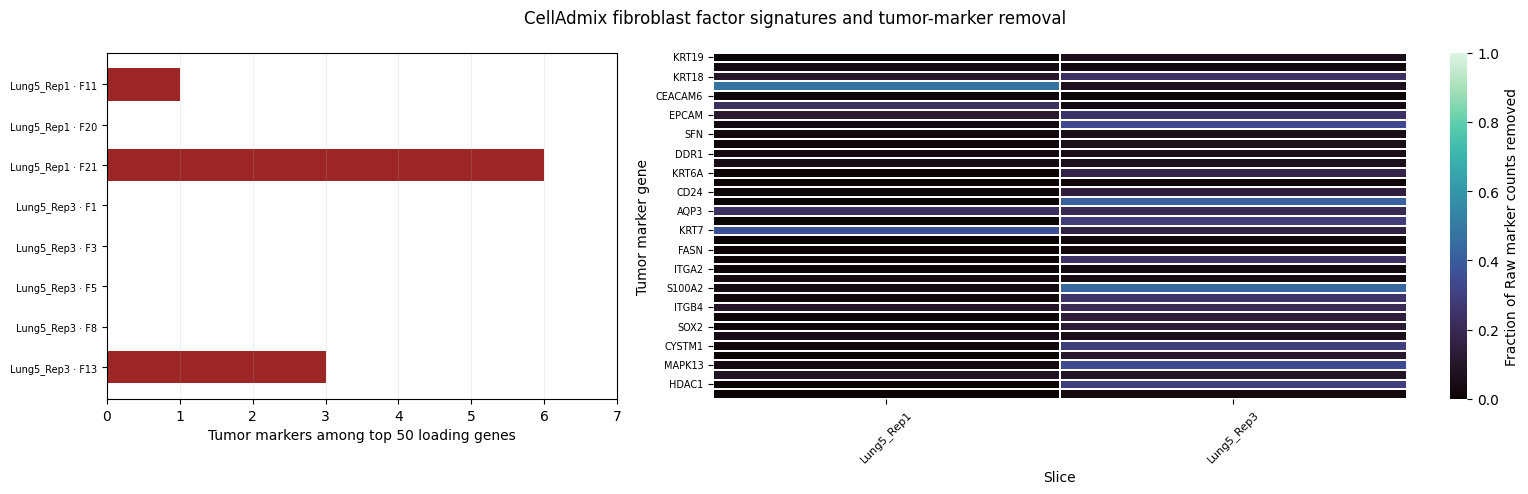

Saved CellAdmix factor/removal tables: /home/jwinchel/Syndri/figures/outputs/cosmx_fibroblast_tutorial/f10ec16a1469b24b


In [13]:
from scipy.stats import hypergeom
from statsmodels.stats.multitest import multipletests
import seaborn as sns
CELLADMIX_FACTOR_ROOT = ROOT / 'competitors/celladmix/factorization_k1p5ct'
CELLADMIX_ANNOTATION_ROOT = ROOT / 'competitors/celladmix/annotation_k1p5ct'
CELLADMIX_CORRECTED_ROOT = ROOT / 'competitors/celladmix_k1p5ct'
CELLADMIX_FACTOR_TOP_N = 50
CELLADMIX_VALIDATION_SLICES = [
    'st_integrated_slice-Lung5_Rep1',
    'st_integrated_slice-Lung5_Rep3',
]
validation_paths = [p for p in paths if p.stem in CELLADMIX_VALIDATION_SLICES]
if {p.stem for p in validation_paths} != set(CELLADMIX_VALIDATION_SLICES):
    raise ValueError('Both Lung5 replicates with CellAdmix output must be present in paths.')
MARKER_OTHER_COLOR = "#bdbdbd"
MARKER_MACROPHAGE_COLOR = "#2676b8"
MARKER_MALIGNANT_COLOR = "#8b0000"
factor_rows = []
factor_status_rows = []
for path in validation_paths:
    slice_name = path.stem
    fit_dir = CELLADMIX_FACTOR_ROOT / slice_name
    annotation_dir = CELLADMIX_ANNOTATION_ROOT / slice_name
    loadings_path = fit_dir / 'factor_loadings.csv'
    factor_map_path = annotation_dir / 'factor_map.csv'
    corrected_path = CELLADMIX_CORRECTED_ROOT / f'{slice_name}.h5ad'
    status_row = {
        'slice': slice_name,
        'factorization_available': loadings_path.is_file(),
        'factor_map_available': factor_map_path.is_file(),
        'celladmix_counts_available': corrected_path.is_file(),
        'n_fibroblast_factors_mapped': 0,
    }
    if not (loadings_path.is_file() and factor_map_path.is_file()):
        factor_status_rows.append(status_row)
        continue

    factor_map = pd.read_csv(factor_map_path)
    fibroblast_factors = sorted(
        factor_map.loc[factor_map.cell_type.eq('Fibroblast'), 'factor'].astype(int).unique()
    )
    status_row['n_fibroblast_factors_mapped'] = len(fibroblast_factors)
    factor_status_rows.append(status_row)
    if not fibroblast_factors:
        continue

    _, var = read_metadata(path)
    symbol_by_id = resolved_gene_symbols(var).to_dict()
    loadings = pd.read_csv(loadings_path)
    loadings['symbol'] = loadings['gene'].astype(str).map(symbol_by_id)
    for factor_id in fibroblast_factors:
        factor_column = f'V{factor_id}'
        if factor_column not in loadings:
            raise KeyError(f'{loadings_path}: missing loading column {factor_column}')
        ranked = (loadings[['symbol', factor_column]]
                  .dropna(subset=['symbol'])
                  .sort_values(factor_column, ascending=False)
                  .drop_duplicates('symbol', keep='first'))
        top = ranked.head(CELLADMIX_FACTOR_TOP_N)
        hits = top.loc[top.symbol.isin(TUMOR_MARKERS), 'symbol'].astype(str).tolist()
        n_background = int(ranked.symbol.nunique())
        n_markers_background = int(ranked.symbol.isin(TUMOR_MARKERS).sum())
        n_top = len(top)
        n_hits = len(hits)
        enrichment_p = float(hypergeom.sf(n_hits - 1, n_background,
                                          n_markers_background, n_top))
        factor_rows.append({
            'slice': slice_name,
            'factor': factor_id,
            'factor_column': factor_column,
            'top_n': n_top,
            'tumor_markers_in_top_n': n_hits,
            'tumor_markers_top_n': ';'.join(hits),
            'background_gene_count': n_background,
            'background_tumor_marker_count': n_markers_background,
            'tumor_marker_enrichment_p': enrichment_p,
            'top_loading_genes': ';'.join(top.symbol.astype(str)),
        })

celladmix_factor_summary = pd.DataFrame(factor_rows)
if not celladmix_factor_summary.empty:
    celladmix_factor_summary['tumor_marker_enrichment_q'] = multipletests(
        celladmix_factor_summary.tumor_marker_enrichment_p,
        method='fdr_bh'
    )[1]

# expression was computed on the saved, common per-slice fibroblast cohort.
marker_expression = expression.loc[
    expression.region.eq('all')
    & expression['slice'].isin(CELLADMIX_VALIDATION_SLICES)
    & expression.gene.isin(TUMOR_MARKERS)
    & expression.method.isin(['Raw', 'CellAdmix']),
    ['slice', 'gene', 'method', 'mean_counts'],
]
marker_wide = marker_expression.pivot_table(
    index=['slice', 'gene'], columns='method', values='mean_counts', aggfunc='first'
).reset_index()
if 'Raw' not in marker_wide:
    marker_wide['Raw'] = np.nan
if 'CellAdmix' not in marker_wide:
    marker_wide['CellAdmix'] = np.nan
marker_wide['removed_mean_counts'] = marker_wide['Raw'] - marker_wide['CellAdmix']
marker_wide['fraction_marker_counts_removed'] = np.where(
    marker_wide['Raw'].gt(0),
    marker_wide['removed_mean_counts'] / marker_wide['Raw'],
    np.nan,
)

removal_summary_rows = []
for slice_name, frame in marker_wide.groupby('slice', sort=False):
    available = frame[['Raw', 'CellAdmix']].notna().all(axis=1)
    frame = frame.loc[available]
    if frame.empty:
        removal_summary_rows.append({
            'slice': slice_name, 'n_markers': 0, 'raw_marker_counts_per_cell': np.nan,
            'celladmix_marker_counts_per_cell': np.nan, 'fraction_marker_counts_removed': np.nan,
            'n_markers_with_any_removal': 0,
        })
        continue
    raw_total = float(frame.Raw.sum())
    cleaned_total = float(frame.CellAdmix.sum())
    removal_summary_rows.append({
        'slice': slice_name,
        'n_markers': len(frame),
        'raw_marker_counts_per_cell': raw_total,
        'celladmix_marker_counts_per_cell': cleaned_total,
        'fraction_marker_counts_removed': (raw_total - cleaned_total) / raw_total if raw_total else np.nan,
        'n_markers_with_any_removal': int(frame.removed_mean_counts.gt(0).sum()),
    })
celladmix_marker_removal_summary = pd.DataFrame(removal_summary_rows)
celladmix_factor_status = pd.DataFrame(factor_status_rows)

factor_path = RUN_DIR / 'celladmix_fibroblast_factor_marker_loadings.csv'
removal_path = RUN_DIR / 'celladmix_tumor_marker_removal_by_gene.csv'
summary_path = RUN_DIR / 'celladmix_tumor_marker_removal_by_slice.csv'
status_path = RUN_DIR / 'celladmix_factor_and_output_availability.csv'
celladmix_factor_summary.to_csv(factor_path, index=False)
marker_wide.to_csv(removal_path, index=False)
celladmix_marker_removal_summary.to_csv(summary_path, index=False)
celladmix_factor_status.to_csv(status_path, index=False)

display(celladmix_factor_status)
display(celladmix_factor_summary.sort_values(
    ['tumor_markers_in_top_n', 'tumor_marker_enrichment_q'], ascending=[False, True]
))
display(celladmix_marker_removal_summary)

# Show factor signatures beside per-gene removal across the same fibroblast cohorts.
fig_height = max(5, 0.28 * max(1, len(celladmix_factor_summary)) + 1.5)
fig, (ax_factor, ax_removal) = plt.subplots(
    1, 2, figsize=(16, fig_height), gridspec_kw={'width_ratios': [1, 1.7]}
)
if celladmix_factor_summary.empty:
    missing(ax_factor, 'No fibroblast-mapped CellAdmix factors')
else:
    factor_plot = celladmix_factor_summary.sort_values(
        ['slice', 'factor'], ascending=[True, True]
    ).copy()
    factor_plot['label'] = factor_plot['slice'].str.removeprefix('st_integrated_slice-') + ' · F' + factor_plot.factor.astype(str)
    y = np.arange(len(factor_plot))
    ax_factor.barh(y, factor_plot.tumor_markers_in_top_n,
                   color=MARKER_MALIGNANT_COLOR, alpha=.85)
    ax_factor.set_yticks(y, factor_plot.label, fontsize=7)
    ax_factor.invert_yaxis()
    ax_factor.set_xlabel(f'Tumor markers among top {CELLADMIX_FACTOR_TOP_N} loading genes')
    ax_factor.set_xlim(0, max(1, int(factor_plot.tumor_markers_in_top_n.max()) + 1))
    ax_factor.grid(axis='x', alpha=.2)

if marker_wide.fraction_marker_counts_removed.notna().any():
    heatmap = marker_wide.pivot(index='gene', columns='slice', values='fraction_marker_counts_removed')
    heatmap = heatmap.reindex(index=TUMOR_MARKERS)
    heatmap.columns = [c.removeprefix('st_integrated_slice-') for c in heatmap.columns]
    sns.heatmap(heatmap, ax=ax_removal, cmap='mako', vmin=0, vmax=1,
                mask=heatmap.isna(), linewidths=.2, linecolor='white',
                cbar_kws={'label': 'Fraction of Raw marker counts removed'})
    ax_removal.set_xlabel('Slice')
    ax_removal.set_ylabel('Tumor marker gene')
    ax_removal.tick_params(axis='x', rotation=45, labelsize=8)
    ax_removal.tick_params(axis='y', labelsize=7)
else:
    missing(ax_removal, 'Matched Raw / CellAdmix marker counts unavailable')
fig.suptitle('CellAdmix fibroblast factor signatures and tumor-marker removal')
fig.tight_layout()
save_figure(fig, 'celladmix_factor_marker_removal_check')
plt.show()
plt.close(fig)
print('Saved CellAdmix factor/removal tables:', RUN_DIR)
